# Tutorial: becas y apoyos educativos en Bogotá con web scraping

**Taller de Python · Facultad de Economía · Universidad de los Andes**

**Integrantes**

- Daniel Eduardo Ramírez Hoyos — 202626865
- Daniel Ricardo Valderrama Celis — 20213250

**Contenido:** 0. Introducción · 1. Paquetes y configuración · 2. Fuentes · 3. Extracción y caché · 4. Limpieza y validación · 5. Análisis · 6. App en Streamlit · 7. Limitaciones · 8. Uso de IA para ir más allá de la metodología · 9. Conclusiones

## 0. Introducción

Este tutorial muestra cómo reunir con web scraping la oferta de becas y apoyos educativos de tres entidades y compararla.
Primero planteamos el problema y la pregunta; cada sección siguiente construye una parte de la respuesta.

**Problema.** La información sobre becas y apoyos educativos para estudiar en Bogotá está repartida en portales distintos (catálogos web, documentos PDF y plataformas con inicio de sesión), y cada entidad la organiza a su manera. Un joven no sabe de entrada a qué tipo de entidad acudir según lo que quiere estudiar: si a un programa público que financia estudios en varias instituciones o a la universidad donde quiere estudiar, ni con qué tipo de ayuda.

**Pregunta.** ¿En qué se diferencian y en qué se complementan los apoyos de una entidad pública que financia estudios en varias instituciones (Agencia Atenea) y los de universidades privadas que financian sus propios programas (Universidad de los Andes y Pontificia Universidad Javeriana)? La comparación se hace según el nivel y el área que quiere estudiar un joven en Bogotá: el tipo de ayuda que ofrecen y qué parte de la matrícula cubren (noviembre de 2026).

**Por qué estas tres entidades.** Representan dos formas de financiar el estudio. La Agencia Atenea es una entidad pública del Distrito que financia estudios en sus instituciones aliadas. La Universidad de los Andes y la Pontificia Universidad Javeriana son universidades privadas que financian sus propios programas; tener dos permite ver si lo que encontramos en una es propio de las universidades privadas o solo de esa universidad.

**Objetivo.** Que un joven pueda ver, según el nivel y el área que quiere estudiar, a qué entidad acudir, con qué tipo de ayuda y cuánto de la matrícula le pueden cubrir. La app de la sección 6 lleva ese resultado a una herramienta de búsqueda, con una portada que resume los hallazgos de este tutorial.

**Alcance.**

- *Término:* "becas y apoyos educativos" incluye becas, subsidios, créditos (condonables o no), descuentos, apoyos de sostenimiento y cursos sin costo.
- *Población:* becas y apoyos que publican la Agencia Atenea (todas las convocatorias de su portal, vigentes o no), la Universidad de los Andes (todos los apoyos de su catálogo) y la Javeriana (las becas de sus páginas para aspirantes y estudiantes, sin los apoyos de movilidad).
- *Periodo:* una foto por fuente: 18 de noviembre de 2026 (Atenea), 22 de noviembre de 2026 (Uniandes) y 27 de noviembre de 2026 (Javeriana).
- *Variables:* nivel de formación, área de conocimiento (las áreas del SNIES, comunes a las tres fuentes), instrumento financiero y qué parte de la matrícula cubre. También el tipo de estudiante (nuevo o antiguo) y las fechas, que solo se usan para saber qué convocatorias siguen vigentes (sección 4) y mostrarlas en la app.

**Cómo atendemos las recomendaciones de la evaluación de la propuesta**

| Recomendación | Dónde se atiende |
|---|---|
| 1. Pregunta que permita responder algo concreto sobre las oportunidades educativas | Pregunta de esta sección; respuesta en las secciones 5 y 9 |
| 2. Extracción de los PDF de Atenea, verificación del acceso a SICORE y al contenido dinámico, enlaces de las secciones de convocatorias | Secciones 2 y 3 |
| 3. Justificar dónde se necesita Selenium y dónde bastan herramientas sencillas; organizar los datos con pandas | Sección 2 (y pandas en todo el tutorial) |
| 4. Identificar convocatorias vencidas y validar la vigencia de requisitos, fechas y enlaces | Sección 4; la app oculta las vencidas (sección 6) |
| 5. Unificar el término "becas y apoyos educativos" | Título, problema y pregunta |

## 1. Paquetes y configuración

Con la pregunta definida, cargamos en una sola celda los paquetes que usa el tutorial.
Las funciones largas de extracción, clasificación y limpieza viven en `utils/scrapers.py`, para que el notebook se lea como un relato.

- `pandas`: organiza todos los datos en DataFrames (esquema común, limpieza y tablas de análisis).
- `matplotlib`: gráficos del análisis.
- `utils.scrapers`: funciones del proyecto. Por dentro usan `requests` (descargas y consulta del catálogo JSON de Uniandes), `BeautifulSoup` (lectura del HTML de las tres fuentes) y `pdfplumber` (lectura de los PDF de Atenea).
- `streamlit` no se importa aquí: lo usa la app (`app.py`), que se explica en la sección 6.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from utils import scrapers

`ACTUALIZAR_DATOS` controla de dónde salen los datos:

- `False` (por defecto): todo se lee de las copias guardadas en `data/raw/` y `results/`. El tutorial corre sin internet y da siempre el mismo resultado.
- `True`: vuelve a raspar las tres fuentes y a validar los enlaces (unos 10 minutos por las pausas entre solicitudes), y sobrescribe las copias. Es la forma de tener la información más reciente: la app de la sección 6 muestra la tabla que deja este notebook.

El tutorial no tiene pasos aleatorios, así que no hace falta fijar una semilla.

In [2]:
ACTUALIZAR_DATOS = False
pd.set_option("display.max_colwidth", 90)

## 2. Fuentes: reconocimiento y elección de herramientas

Antes de raspar revisamos cada fuente: qué permite su `robots.txt`, si el contenido viene en el HTML o se arma con JavaScript, y si hay PDF o inicio de sesión.
Esa revisión decide qué herramienta usar en cada caso y qué queda fuera del alcance.

La revisión la hizo `scripts/01_reconocimiento_fuentes.py`, que consulta las páginas en línea, y guardó su resultado en `results/reconocimiento_fuentes.csv`. Es la revisión del 18 de noviembre de 2026: para Uniandes proponía recorrer el `sitemap.xml`, pero después encontramos el servicio JSON que alimenta su buscador, que lista más apoyos y publica el nivel, el instrumento y los programas de cada uno (se explica debajo de la tabla). La Javeriana se agregó el 27 de noviembre de 2026 y su revisión se muestra con las páginas guardadas, al final de esta sección.

In [3]:
reconocimiento = pd.read_csv("results/reconocimiento_fuentes.csv")
# La revisión también incluyó al SENA (Betowa), que quedó fuera de la pregunta.
reconocimiento = reconocimiento[~reconocimiento["fuente"].str.startswith("SENA")]
reconocimiento[["fuente", "url_convocatorias", "contenido_en_html", "pdf", "requiere_login", "herramienta"]]

,fuente,url_convocatorias,contenido_en_html,pdf,requiere_login,herramienta
0,Universidad de los Andes (Apoyo Financiero),https://apoyofinanciero.uniandes.edu.co/explora-apoyos-financieros,Parcial. El buscador de 'Explora' es un iframe (https://apoyofinanciero.uniandes.edu.c...,"Sí, reglamentos en PDF; no hacen falta para el esquema (cobertura y fechas están en la...",No,requests + BeautifulSoup
1,Agencia Atenea (portal de convocatorias),https://www.agenciaatenea.gov.co/convocatorias,"Sí. 7 páginas (?page=0 a 6), 15 tarjetas en la primera, cada una con su estado. 15 de ...",Sí. 12 de 15 convocatorias enlazan PDF y 10 publican un 'lineamiento operativo' con lo...,No para consultar; la inscripción se hace en SICORE.,requests + BeautifulSoup; pdfplumber para los PDF
2,Agencia Atenea (SICORE),https://sicore.agenciaatenea.gov.co/,No. Sin JavaScript la página solo tiene 20 caracteres de texto (aplicación que se arma...,No,Sí. 2 convocatorias de Atenea indican ingresar con usuario y contraseña.,Fuera del alcance


**Secciones de convocatorias de cada entidad**

| Entidad | Sección | Lo que se recorre |
|---|---|---|
| Universidad de los Andes | https://apoyofinanciero.uniandes.edu.co/explora-apoyos-financieros | Catálogo JSON del buscador (`https://segmentador.mundosoft.com.co/api/backend/supports` y `/programs`) y la ficha HTML de cada apoyo, para las fechas |
| Agencia Atenea | https://www.agenciaatenea.gov.co/convocatorias | Listado (`?page=0` a `?page=6`), detalle de cada convocatoria y PDF de lineamiento |
| Pontificia Universidad Javeriana | https://www.javeriana.edu.co/apoyo-financiero/becas-y-descuentos | Tres páginas de becas: aspirantes de pregrado, aspirantes de posgrado y estudiantes de pregrado |
| Agencia Atenea (SICORE) | https://sicore.agenciaatenea.gov.co/ | Nada: exige usuario y contraseña |

**¿Dónde hace falta Selenium y dónde bastan herramientas más sencillas?**

Selenium sirve cuando la información solo aparece después de que el navegador ejecuta JavaScript. Revisamos fuente por fuente:

- **Uniandes.** El buscador de "Explora" es un iframe que se arma con JavaScript. En vez de ejecutarlo con Selenium, consultamos con `requests` el servicio JSON del que el buscador toma sus datos, con los encabezados que envía el propio buscador. Ese servidor tiene un `robots.txt` sin reglas que lo prohíban; las rutas bloqueadas en el `robots.txt` de `apoyofinanciero.uniandes.edu.co` (`/apoyos/index.html` y `/api/`) no se usan. El JSON trae nombre, tipo de apoyo, niveles, facultades y programas, pero no las fechas: esas salen de la ficha HTML de cada apoyo. Herramientas: `requests` (JSON) + `BeautifulSoup` (fichas).
- **Atenea.** El listado y el detalle son HTML estático (Drupal), y las fechas vienen en etiquetas `<time datetime>`. Los requisitos suelen estar en un PDF de "lineamiento operativo". Herramientas: `requests` + `BeautifulSoup`, y `pdfplumber` para los PDF.
- **Javeriana.** Su `robots.txt` permite las páginas de becas, que son HTML estático: cada beca es un acordeón con su título y su texto completo. Herramientas: `requests` + `BeautifulSoup`. Las páginas de descuentos y de becas de posgrado para estudiantes (esta última en el dominio `intranet`) no usan acordeones y quedan fuera.
- **SICORE.** Es una aplicación de JavaScript con inicio de sesión. Selenium podría abrirla, pero los datos están detrás de una cuenta y no son públicos, así que queda fuera del alcance.

Conclusión: ninguna fuente pública necesita Selenium. Preferimos `requests`, que es más rápido, más fácil de reproducir y menos frágil ante cambios de diseño. Todos los datos se organizan con `pandas` en un esquema común.

**¿Cómo verificamos el acceso a SICORE y al contenido dinámico?**

- *SICORE:* sin ejecutar JavaScript, la página solo tiene 20 caracteres de texto. Además, las propias convocatorias de Atenea indican que hay que ingresar "con el usuario y contraseña creados en su inscripción".
- *Uniandes:* el catálogo JSON trae 54 apoyos, frente a los 18 con ficha completa que encontramos recorriendo el `sitemap.xml`: el sitemap no listaba toda la oferta. Por eso cambiamos de método.

**¿Cómo extraemos los PDF de Atenea?**

- Solo se descargan los PDF de "lineamiento operativo" de las convocatorias que no están finalizadas: a quien busca hoy no le sirven los requisitos de una convocatoria cerrada.
- `pdfplumber` extrae el texto y la función `scrapers.extraer_requisitos_pdf` busca el título "Requisitos … de participación". Descarta las líneas del índice y las definiciones del glosario, y corta la sección en el siguiente título numerado (máximo 3.000 caracteres).

**Reconocimiento de la Javeriana.** Cuántas becas (acordeones) tiene cada página guardada y en qué secciones están. Los apoyos de movilidad (intercambios y prácticas en el exterior) financian estancias fuera de la universidad, no el estudio en ella, y se excluyen en la lectura:

In [4]:
acordeones = scrapers.acordeones_javeriana()
acordeones.groupby(["pagina", "seccion"]).size().rename("becas").to_frame()

becas
pagina                                     seccion                                                
/apoyo-financiero/beca-aspirante/posgrado  Apoyos para estudiantes de grupos étnicos             1
                                           Becas para programas de posgrado                      3
                                           Becas y apoyos por movilidad                          1
                                           Créditos condonables                                  3
/apoyo-financiero/beca-aspirantes/pregado  Apoyo para estudiantes de grupos étnicos              1
                                           Becas por excelencia académica                        3
                                           Becas por necesidad económica y otras categorías      5
/apoyo-financiero/beca-estudiante/pregrado Apoyos para estudiantes de grupos étnicos             1
                                           Becas por excelencia académica                        1
                                           Becas por necesidad económica y otras categorías      4
                                           Becas y apoyos por movilidad                          7
                                           Estimulos financieros                                 1

## 3. Extracción y caché

Con la herramienta de cada fuente definida, extraemos los datos a un esquema común que incluye las tres variables de la pregunta.
Guardamos copias crudas con su fecha, para que el tutorial corra sin internet y se pueda rastrear de dónde salió cada dato.

**Descarga (`scrapers.descargar_*`).** Para cada fuente:

- Lee el `robots.txt` y omite lo que no está permitido.
- Espera 2 segundos entre solicitudes.
- Guarda cada respuesta en `data/raw/<fuente>/`: el HTML comprimido (`.html.gz`), los PDF tal cual y, en Uniandes, los catálogos JSON (`.json`).
- Escribe un `manifiesto.csv` con la URL, el archivo, el código HTTP y la fecha de extracción.

In [5]:
if ACTUALIZAR_DATOS:
    scrapers.descargar_uniandes()
    scrapers.descargar_atenea()
    scrapers.descargar_javeriana()

# Resumen de lo que hay en la caché: archivos por tipo de página.
pd.DataFrame({fuente: scrapers.leer_manifiesto(fuente).groupby("tipo_pagina").size()
              for fuente in ["uniandes", "atenea", "javeriana"]}).fillna(0).astype(int)

,uniandes,atenea,javeriana
tipo_pagina,,,
api_programs,1,0,0
api_supports,1,0,0
becas,0,0,3
detalle,0,68,0
ficha,52,0,0
lineamiento,0,4,0
listado,0,8,0


**Lectura (`scrapers.leer_*`).** Convierte los archivos crudos en un DataFrame con el esquema común: `nombre`, `entidad`, `nivel_formacion`, `instrumento`, `area`, `programas`, `cobertura`, `requisitos`, `fecha_apertura`, `fecha_cierre`, `enlace`, `fuente_url` y `fecha_extraccion`, más columnas adicionales como `tipo_estudiante`, `descripcion` (el texto completo que describe el apoyo) y `area_conocimiento`. Lo que una fuente no publica queda como `NaN`; nunca se rellena con datos inventados. Un apoyo puede tener varios niveles, instrumentos o áreas, separados por "; ".

- **Uniandes** publica las tres variables en su catálogo: nivel (`nivelAcadémico`), tipo de apoyo (`tipoDeApoyo`), facultades y programas. Los códigos se traducen a nombres con el catálogo de programas, y el tipo de apoyo se agrupa en las categorías comunes (por ejemplo, "Préstamo" pasa a "Crédito"; el original queda en `instrumento_publicado`).
- **Javeriana** publica cada beca en una página según el nivel (pregrado o posgrado) y el tipo de estudiante (aspirante o estudiante). En posgrado, el nivel exacto se busca en el nombre y el texto; si no lo dice, se asumen los tres niveles de posgrado (inferido). El instrumento es crédito condonable si el nombre o la sección lo dicen, y beca en los demás casos (inferido). No publica fechas.
- **Atenea** no las publica en campos aparte. Se deducen (inferido) con reglas de palabras clave sobre el nombre y los primeros 1.000 caracteres de la descripción, donde cada convocatoria dice qué financia. Más adelante muchas páginas listan documentos o requisitos de exclusión ("no haber cursado un programa técnico, tecnológico o universitario"), que darían falsos positivos. Si ninguna regla aplica, el campo queda en `NaN`.
- **Porcentaje de la matrícula** (`porcentaje_min`, `porcentaje_max`, `forma_porcentaje`): `scrapers.extraer_porcentaje_matricula` lo toma del texto de cobertura cuando la palabra "matrícula" aparece justo después del número, para no confundirlo con "100 % condonables" o "1 % de mejores resultados". Distingue tres formas: valor fijo ("Cubre 95 %"), tope ("hasta el 90 %") y rango ("del 25 % hasta el 95 %").
- **Área de conocimiento** (`area_conocimiento`, inferido): para comparar las tres fuentes usamos las áreas de conocimiento del SNIES (Ministerio de Educación). Las facultades de Uniandes y los sectores que declaran los cursos de Atenea se traducen a esas áreas con las tablas de abajo. Los apoyos que no restringen el área (casi todos los de Atenea y la Javeriana) quedan como "Cualquier área": sirven para los programas que ofrezca la institución.
- La columna `origen_clasificacion` dice de dónde salió cada clasificación. Estas son las reglas de Atenea y las correspondencias con las áreas del SNIES:

In [6]:
reglas = pd.DataFrame([(variable, categoria, patron)
                       for variable, diccionario in [("nivel_formacion", scrapers.NIVELES_ATENEA),
                                                     ("instrumento", scrapers.INSTRUMENTOS_ATENEA),
                                                     ("area", scrapers.AREAS_ATENEA)]
                       for categoria, patron in diccionario.items()],
                      columns=["variable", "categoría", "patrón (expresión regular)"])
with pd.option_context("display.max_colwidth", None):
    display(reglas)

# Correspondencia con las áreas de conocimiento del SNIES (inferido), común a las tres fuentes.
areas = pd.DataFrame([(fuente, categoria, scrapers.SEPARADOR.join(lista))
                      for fuente, diccionario in [("Uniandes (facultad)", scrapers.AREA_FACULTAD_UNIANDES),
                                                  ("Atenea (sector declarado)", scrapers.AREA_SECTOR_ATENEA)]
                      for categoria, lista in diccionario.items()]
                     + [("Javeriana (nombre de la beca)", patron, area)
                        for area, patron in scrapers.AREAS_NOMBRE_JAVERIANA.items()],
                     columns=["fuente", "categoría o patrón", "área del SNIES"])
with pd.option_context("display.max_colwidth", None):
    display(areas)

,variable,categoría,patrón (expresión regular)
0,nivel_formacion,Formación para el trabajo y cursos cortos,formaci[oó]n para el trabajo|t[eé]cnicos?[- ]laboral|ciclos? cortos?|talento capital|todos a la u|cursos? (?:de formaci[oó]n|virtual|gratuit)|el curso es gratuito|ingl[eé]s|habilidades digitales|\betdh\b
1,nivel_formacion,Técnico y tecnológico,t[eé]cnic[oa]s?[- ]profesional|tecnol[oó]gic[oa]s?\b|t[eé]cnica y tecnol
2,nivel_formacion,Pregrado universitario,universitari|pregrado|universidades?:
3,nivel_formacion,Especialización,especializaci[oó]n
4,nivel_formacion,Maestría,maestr[ií]a
5,nivel_formacion,Doctorado,doctorado
6,instrumento,Beca o subsidio de matrícula,"\bbecas?\b|\bsubsidi|cubre[^.]{0,40}matr[ií]cula|valor de la matr[ií]cula"
7,instrumento,Crédito condonable,condonable
8,instrumento,Crédito con pago contingente,contingente
9,instrumento,Apoyo de sostenimiento,sostenimiento|apoyo econ[oó]mico|canasta


,fuente,categoría o patrón,área del SNIES
0,Uniandes (facultad),Administración,"Economía, administración, contaduría y afines"
1,Uniandes (facultad),Arquitectura y Diseño,"Ingeniería, arquitectura, urbanismo y afines; Bellas artes"
2,Uniandes (facultad),Artes y Humanidades,Bellas artes; Ciencias sociales y humanas
3,Uniandes (facultad),Ciencias,Matemáticas y ciencias naturales
4,Uniandes (facultad),Ciencias Sociales,Ciencias sociales y humanas
5,Uniandes (facultad),Derecho,Ciencias sociales y humanas
6,Uniandes (facultad),Economía,"Economía, administración, contaduría y afines"
7,Uniandes (facultad),Educación,Ciencias de la educación
8,Uniandes (facultad),Esc de Gobierno Alberto Lleras,Ciencias sociales y humanas
9,Uniandes (facultad),Ingeniería,"Ingeniería, arquitectura, urbanismo y afines"


In [7]:
becas_apoyos = pd.concat([scrapers.leer_uniandes(), scrapers.leer_atenea(), scrapers.leer_javeriana()],
                         ignore_index=True)
becas_apoyos.to_csv("results/extraccion_sin_limpiar.csv", index=False, encoding="utf-8-sig")
becas_apoyos.groupby(["entidad", "origen_clasificacion"]).size().to_frame("registros")

Uniandes: 54 apoyos procesados desde el segmentador y fichas web


Atenea: 68 convocatorias


Javeriana: 19 becas (sin las de movilidad)


,,registros
entidad,origen_clasificacion,
Agencia Atenea,reglas de texto (inferido),68
Pontificia Universidad Javeriana,página de la entidad y reglas de texto (inferido),19
Universidad de los Andes,catálogo de la entidad,54


Una muestra de tres registros por entidad, para ver cómo quedan las tres variables antes de limpiar:

In [8]:
becas_apoyos.groupby("entidad").head(3)[["entidad", "nombre", "nivel_formacion", "instrumento", "tipo_estudiante", "area_conocimiento"]]

,entidad,nombre,nivel_formacion,instrumento,tipo_estudiante,area_conocimiento
0,Universidad de los Andes,Beca con compromiso Quiero Estudiar,Pregrado universitario,Beca o subsidio de matrícula,Estudiante Nuevo,Bellas artes; Ciencias de la educación; Ciencias de la salud; Ciencias sociales y huma...
1,Universidad de los Andes,Beca con compromiso Quiero Enseñar,Pregrado universitario,Beca o subsidio de matrícula,Estudiante Nuevo,Ciencias de la educación
2,Universidad de los Andes,Beca con compromiso Fondo Dora Rothlisberger,Pregrado universitario,Beca o subsidio de matrícula,Estudiante Antiguo,Ciencias sociales y humanas
54,Agencia Atenea,Convocatoria Jóvenes a la E: Formación para el Trabajo 5,Formación para el trabajo y cursos cortos,NaN,NaN,Cualquier área
55,Agencia Atenea,Fondo Técnica y Tecnológica,Técnico y tecnológico,Beca o subsidio de matrícula; Apoyo de sostenimiento,NaN,Cualquier área
56,Agencia Atenea,Fondo Alianza Ciudad Educadora,NaN,Crédito condonable; Apoyo de sostenimiento,NaN,Cualquier área
122,Pontificia Universidad Javeriana,Beca Bachiller Destacado,Pregrado universitario,Beca o subsidio de matrícula,Estudiante Nuevo,Cualquier área
123,Pontificia Universidad Javeriana,Beca Bachiller Destacado Colegios ACODESI,Pregrado universitario,Beca o subsidio de matrícula,Estudiante Nuevo,Cualquier área
124,Pontificia Universidad Javeriana,Beca Bachiller Destacado FE Y ALEGRÍA,Pregrado universitario,Beca o subsidio de matrícula,Estudiante Nuevo,Cualquier área


## 4. Limpieza y validación

La extracción deja texto crudo, fechas en formatos distintos y convocatorias que no son apoyos para estudiar.
Aquí revisamos tipos, faltantes, duplicados y atípicos, definimos el alcance, e identificamos las convocatorias vencidas y los enlaces válidos.

### 4.1 Tipos y faltantes

Todas las columnas llegan como texto, porque cada fuente publica las fechas en un formato distinto. Los faltantes **no se rellenan**: un `NaN` significa que la entidad no publica ese dato o que ninguna regla lo encontró, y eso también es un resultado (ver la sección 5).

In [9]:
COLUMNAS_TEXTO = ["nombre", "cobertura", "requisitos"]
COLUMNAS_CLASIFICACION = ["nivel_formacion", "instrumento", "area"]
COLUMNAS_FECHA = ["fecha_apertura", "fecha_cierre", "fecha_extraccion"]

print(becas_apoyos.dtypes.value_counts().to_dict())
becas_apoyos[COLUMNAS_CLASIFICACION + COLUMNAS_TEXTO + COLUMNAS_FECHA].isna().groupby(becas_apoyos["entidad"]).sum()

{<StringDtype(na_value=nan)>: 15, dtype('O'): 6, dtype('float64'): 3}


,nivel_formacion,instrumento,area,nombre,cobertura,requisitos,fecha_apertura,fecha_cierre,fecha_extraccion
entidad,,,,,,,,,
Agencia Atenea,17,37,54,0,0,62,2,5,0
Pontificia Universidad Javeriana,0,0,16,0,3,4,19,19,0
Universidad de los Andes,0,0,0,0,0,0,20,20,0


### 4.2 Duplicados

Un registro está duplicado si repite el enlace **y** el nombre. Varios apoyos distintos pueden compartir una página: las becas de la Javeriana están en tres páginas, y en Uniandes dos becas de maestrías virtuales comparten ficha. Los nombres repetidos con enlaces distintos son aperturas distintas del mismo programa (por ejemplo, dos convocatorias del mismo fondo en fechas distintas) y también se conservan. Solo hay un duplicado real: un apoyo de Uniandes que el catálogo repite.

In [10]:
print("Filas idénticas:", becas_apoyos.duplicated().sum(),
      "| enlace y nombre repetidos:", becas_apoyos.duplicated(["enlace", "nombre"]).sum())
becas_apoyos = becas_apoyos.drop_duplicates(subset=["enlace", "nombre"])
becas_apoyos[becas_apoyos.duplicated(["entidad", "nombre"], keep=False)][["entidad", "nombre", "fecha_apertura", "enlace"]]

Filas idénticas: 0 | enlace y nombre repetidos: 1


,entidad,nombre,fecha_apertura,enlace
16,Universidad de los Andes,Préstamo Mediano Plazo 2048,19 de octubre de 2026,https://apoyofinanciero.uniandes.edu.co/prestamo-mediano-plazo-20482
22,Universidad de los Andes,Préstamo Mediano Plazo 2048,14 de agostro de 2026,https://apoyofinanciero.uniandes.edu.co/prestamo-mediano-plazo-2048
79,Agencia Atenea,Fondo para Víctimas del Conflicto,2025-12-04,https://www.agenciaatenea.gov.co/convocatorias/fondo-para-victimas-del-conflicto-0
90,Agencia Atenea,Fondo para Víctimas del Conflicto,2025-06-05,https://www.agenciaatenea.gov.co/convocatorias/fondo-para-victimas-del-conflicto


### 4.3 Texto y fechas

- **Texto:** se quitan caracteres invisibles (algunas páginas de Atenea tienen espacios de ancho cero), espacios repetidos y espacios antes de las comas. No se cambia el contenido.
- **Fechas:** pasan a `datetime` en hora de Bogotá. Atenea publica en formato ISO con zona horaria (`2026-11-24T23:59:00-05:00`) o solo la fecha; Uniandes, como "26 de noviembre de 2026" (a veces "del 2026"); la Javeriana no publica fechas en sus páginas de becas. La función `scrapers.texto_a_fecha` acepta esos formatos y devuelve `NaT` si no reconoce uno, para no inventar fechas.
- **Comprobación:** contamos cuántas fechas publicadas no se pudieron convertir.

In [11]:
for columna in COLUMNAS_TEXTO:
    becas_apoyos[columna] = becas_apoyos[columna].map(scrapers.limpiar_cadena)

fechas_sin_convertir = {}
for columna in COLUMNAS_FECHA:
    convertidas = becas_apoyos[columna].map(scrapers.texto_a_fecha)
    fechas_sin_convertir[columna] = int((becas_apoyos[columna].notna() & convertidas.isna()).sum())
    becas_apoyos[columna] = pd.to_datetime(convertidas)
print("Fechas publicadas que no se pudieron convertir:", fechas_sin_convertir)
becas_apoyos[COLUMNAS_FECHA].dtypes

Fechas publicadas que no se pudieron convertir: {'fecha_apertura': 0, 'fecha_cierre': 0, 'fecha_extraccion': 0}


fecha_apertura      datetime64[us]
fecha_cierre        datetime64[us]
fecha_extraccion    datetime64[us]
dtype: object

### 4.4 Valores atípicos en las fechas

Las fechas no se analizan, pero sí se revisa que estén bien extraídas: cierres anteriores a la apertura (un error de publicación o de extracción) y ventanas de inscripción muy largas. No se borran; si aparecen, se marcan como alerta en la sección 4.8.

In [12]:
becas_apoyos["dias_ventana"] = (becas_apoyos["fecha_cierre"] - becas_apoyos["fecha_apertura"]).dt.days
print("Cierres antes de la apertura:", int((becas_apoyos["dias_ventana"] < 0).sum()))
becas_apoyos.groupby("entidad")["dias_ventana"].describe().round(1)

Cierres antes de la apertura: 0


,count,mean,std,min,25%,50%,75%,max
entidad,,,,,,,,
Agencia Atenea,63.0,27.7,27.6,2.0,7.0,18.0,32.0,115.0
Pontificia Universidad Javeriana,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Universidad de los Andes,34.0,52.0,42.2,6.0,18.0,33.5,86.0,123.0


No hay cierres anteriores a la apertura. Las ventanas más largas de Atenea (más de 90 días) corresponden a convocatorias para proyectos de investigación, que salen del alcance en el paso siguiente. En Uniandes las ventanas van de 6 a 123 días: las largas son apoyos que reciben solicitudes durante buena parte del semestre (inferido). Son plazos publicados, no errores.

### 4.5 Alcance: becas y apoyos educativos para personas

La pregunta es sobre apoyos para estudiar. Algunas convocatorias de Atenea financian proyectos de investigación, empresas (Mipymes) o prácticas laborales: no son apoyos educativos para una persona y se excluyen.

La regla es explícita (`scrapers.PATRON_NO_ESTUDIANTES`). "Prácticas laborales" solo cuenta si aparece en el nombre, porque algunos programas de formación la mencionan como un beneficio más. La lista de excluidas se muestra para que se pueda verificar.

In [13]:
para_personas = [scrapers.dirigido_a_personas(n, c) for n, c in zip(becas_apoyos["nombre"], becas_apoyos["cobertura"])]
excluidas = becas_apoyos.loc[[not x for x in para_personas], ["entidad", "nombre"]]
becas_apoyos = becas_apoyos[para_personas].reset_index(drop=True)
print(f"Se excluyen {len(excluidas)} convocatorias; quedan {len(becas_apoyos)} registros.")
excluidas

Se excluyen 14 convocatorias; quedan 126 registros.


,entidad,nombre
60,Agencia Atenea,"Retos de Investigación en Salud, Vejez y Envejecimiento 2026"
73,Agencia Atenea,Programa Bogotá Científica Convocatoria Retos de Investigación en Salud - Sustancias P...
74,Agencia Atenea,LISTOS para '+MAS Bienestar' 2026
83,Agencia Atenea,Retos de innovación Academia Atenea
87,Agencia Atenea,LISTOS para 'MAS Bienestar'
98,Agencia Atenea,Prácticas laborales en la Agencia Atenea - Periodo 2025-I
99,Agencia Atenea,COOPERACIÓN PARA EL DISEÑO Y EJECUCIÓN DE PROYECTOS DE INVESTIGACIÓN ENFOCADOS EN LA S...
102,Agencia Atenea,Convocatoria Investigación para la toma de decisiones en salud mental en Bogotá
109,Agencia Atenea,"Convocatoria EcoCambio – Bogotá, ejemplo global de sostenibilidad"
112,Agencia Atenea,Convocatoria Cooperación para la gestión y ejecución de proyectos de investigación en ...


### 4.6 Vigencia: convocatorias vencidas

La app solo debe mostrar convocatorias a las que todavía se puede aplicar. Así identificamos las vencidas (`scrapers.calcular_estado`), comparando cada registro con la fecha de extracción de su fuente (18 de noviembre en Atenea, 22 de noviembre en Uniandes y 27 de noviembre en la Javeriana):

1. **Con fecha de cierre publicada:**
   - "próxima" si todavía no abre;
   - "abierta" si cierra el día de la extracción o después;
   - "cerrada" (vencida) si ya cerró.
2. **Sin fecha de cierre, pero con un estado publicado por la entidad (Atenea):** se usa ese estado.
3. **En otro caso:** "sin fecha". Es el caso de las 19 becas de la Javeriana y de 19 apoyos de Uniandes: son becas permanentes de su catálogo, y la fecha se consulta en su enlace.

La columna `criterio_estado` dice qué regla se aplicó a cada registro. Las cerradas siguen en el análisis (dicen a qué se dedica cada entidad), pero no aparecen en la app.

In [14]:
becas_apoyos[["estado", "criterio_estado"]] = becas_apoyos.apply(scrapers.calcular_estado, axis=1, result_type="expand")
pd.crosstab(becas_apoyos["entidad"], becas_apoyos["estado"])

estado,abierta,cerrada,próxima,sin fecha
entidad,,,,
Agencia Atenea,3,47,3,1
Pontificia Universidad Javeriana,0,0,0,19
Universidad de los Andes,16,8,10,19


**Validación de las fechas.** Atenea publica su propio estado en el listado. Si nuestras fechas son correctas, el estado calculado debe coincidir con el publicado:

In [15]:
atenea_limpia = becas_apoyos[becas_apoyos["entidad"] == "Agencia Atenea"]
pd.crosstab(atenea_limpia["estado"], atenea_limpia["estado_publicado"])

estado_publicado,Apertura: Diciembre de 2026,En curso,Finalizada,Inscripciones abiertas
estado,,,,
abierta,0,0,0,3
cerrada,0,0,47,0
próxima,3,0,0,0
sin fecha,0,1,0,0


Coinciden en todos los casos comparables: lo que calculamos como "abierta", "cerrada" o "próxima" es lo que Atenea publica como "Inscripciones abiertas", "Finalizada" o "Apertura: …". La única convocatoria "En curso" no tiene fechas publicadas y queda "sin fecha". Uniandes no publica un estado propio en el catálogo, así que sus fechas no se pueden validar de esta forma.

**Vigencia de los requisitos.** Los requisitos se toman solo de la página o del catálogo de la propia convocatoria, o del PDF de lineamiento enlazado desde ella, nunca de manuales de convocatorias anteriores. Cuando no hay requisitos, el registro queda marcado (sección 4.8) en lugar de completarse con otra fuente.

### 4.7 Validación de enlaces

Un enlace es válido si respondió con código HTTP 200. Con `ACTUALIZAR_DATOS = True`, `scrapers.validar_enlaces` visita cada enlace (respetando `robots.txt` y con pausas) y guarda el resultado en `results/validacion_enlaces.csv`. Con `False` usa ese resultado guardado y solo visita los enlaces que todavía no estén en él. Así, un enlace sin revisar nunca se da por no válido. La columna `fecha_validacion` dice cuándo se revisó cada enlace.

In [16]:
validacion = scrapers.validar_enlaces(becas_apoyos["enlace"], ACTUALIZAR_DATOS)
becas_apoyos = becas_apoyos.merge(validacion[["enlace", "codigo_http", "fecha_validacion"]], on="enlace", how="left")
becas_apoyos["enlace_valido"] = becas_apoyos["codigo_http"] == 200
becas_apoyos.groupby(["entidad", "fecha_validacion"])["enlace_valido"].agg(validos="sum", total="count")

validos  total
entidad                          fecha_validacion                
Agencia Atenea                   2026-11-18             54     54
Pontificia Universidad Javeriana 2026-11-27             19     19
Universidad de los Andes         2026-11-18             14     14
                                 2026-11-26             39     39

### 4.8 Alertas de calidad y tabla final

Cada registro lleva una lista de lo que un aspirante debería verificar antes de confiar en él: falta de requisitos, falta de fecha de cierre, enlace no válido o cierre antes de la apertura.

En las convocatorias cerradas de Atenea, "sin requisitos" es esperado, porque sus PDF no se descargan. En la Javeriana, "sin fecha de cierre" también es esperado. La tabla final queda en `results/becas_apoyos.csv` y es la que leen el análisis y la app.

In [17]:
# scrapers.alertas_de marca: sin requisitos, sin fecha de cierre, enlace no válido y cierre antes de apertura.
becas_apoyos["alertas"] = becas_apoyos.apply(scrapers.alertas_de, axis=1)
becas_apoyos = becas_apoyos[scrapers.COLUMNAS_FINALES]
becas_apoyos.to_csv("results/becas_apoyos.csv", index=False, encoding="utf-8-sig")
becas_apoyos.groupby("entidad")["alertas"].value_counts(dropna=False).to_frame("registros")

registros
entidad                          alertas                                       
Agencia Atenea                   sin requisitos                              45
                                 NaN                                          4
                                 sin requisitos; sin fecha de cierre          4
                                 sin fecha de cierre                          1
Pontificia Universidad Javeriana sin fecha de cierre                         15
                                 sin requisitos; sin fecha de cierre          4
Universidad de los Andes         NaN                                         34
                                 sin fecha de cierre                         19

## 5. Análisis: nivel, área, instrumento y parte de la matrícula

Con la tabla limpia comparamos las tres entidades en las variables de la pregunta: a qué niveles se dirigen (5.1), con qué instrumentos (5.2), qué parte de la matrícula cubren (5.3), cómo se combinan nivel e instrumento (5.4) y a qué áreas de conocimiento sirven (5.5).
Los porcentajes son sobre los registros de cada entidad: un apoyo puede tener varias categorías, así que una columna puede sumar más de 100 %. En Atenea un registro es una convocatoria (vigente o pasada); en las universidades, un apoyo de su catálogo (en la sección 8 se repite la medición por línea de apoyo).

Antes, definimos el estilo común de los gráficos (un color fijo por entidad, de la paleta Okabe-Ito, apta para daltonismo) y dos funciones: una que separa las categorías múltiples y otra que calcula los porcentajes.

In [18]:
# Primero la entidad pública; después las dos universidades privadas.
ENTIDADES = ["Agencia Atenea", "Universidad de los Andes", "Pontificia Universidad Javeriana"]
UNIVERSIDADES = ENTIDADES[1:]
NOMBRE_CORTO = {"Agencia Atenea": "Atenea", "Universidad de los Andes": "Uniandes",
                "Pontificia Universidad Javeriana": "Javeriana"}
# Un color fijo por entidad (paleta Okabe-Ito, apta para daltonismo).
COLOR_ENTIDAD = {"Agencia Atenea": "#E69F00", "Universidad de los Andes": "#0072B2",
                 "Pontificia Universidad Javeriana": "#009E73"}
ORDEN_NIVEL = ["Formación para el trabajo y cursos cortos", "Técnico y tecnológico", "Pregrado universitario",
               "Especialización", "Maestría", "Doctorado"]
ORDEN_INSTRUMENTO = ["Beca o subsidio de matrícula", "Descuento", "Crédito", "Crédito condonable",
                     "Crédito con pago contingente", "Apoyo de sostenimiento", "Formación sin costo"]
SIN_DATO = "Sin dato publicado"
# Cada fuente se extrajo en su propia fecha; el pie de las figuras las indica todas.
FECHAS = becas_apoyos.groupby("entidad")["fecha_extraccion"].max().dt.strftime("%Y-%m-%d")
PIE_FIGURA = ("Fuente: " + ", ".join(f"{NOMBRE_CORTO[e]} (extraído el {FECHAS[e]})" for e in ENTIDADES)
              + ". Atenea y Javeriana: categorías inferidas con reglas de texto. Elaboración: tutorial.ipynb")
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#888888", "axes.grid": True, "grid.color": "#E5E5E5",
                     "axes.axisbelow": True})


def guardar_figura(figura, nombre):
    """Agrega el pie de fuente, guarda la figura en figures/ y la muestra."""
    figura.tight_layout()
    figura.text(0.01, 0.0, PIE_FIGURA, fontsize=7, color="#666666", va="top")
    figura.savefig(f"figures/{nombre}", dpi=150, bbox_inches="tight")
    plt.show()


def separar(base, columna):
    """Una fila por registro y categoría: un apoyo con dos niveles aparece dos veces.
    Los registros sin dato quedan con la categoría SIN_DATO, para que se vean en las tablas."""
    largo = base.assign(**{columna: base[columna].fillna(SIN_DATO).str.split(scrapers.SEPARADOR)})
    return largo.explode(columna)


def porcentaje_por_categoria(base, columna, orden):
    """% de registros de cada entidad que incluye cada categoría. La última fila es el número de registros (n)."""
    largo = separar(base, columna)
    conteo = pd.crosstab(largo[columna], largo["entidad"]).reindex(columns=ENTIDADES, fill_value=0)
    tabla = (conteo / base["entidad"].value_counts()[ENTIDADES] * 100).round(1)
    tabla = tabla.reindex([c for c in orden + [SIN_DATO] if c in tabla.index])
    tabla.loc["Registros (n)"] = base["entidad"].value_counts()[ENTIDADES]
    return tabla


def grafico_barras(tabla, titulo, eje_x, nombre):
    """Barras horizontales agrupadas: % de registros de cada entidad por categoría."""
    tabla = tabla.drop(index="Registros (n)")
    figura, eje = plt.subplots(figsize=(8, 0.85 * len(tabla) + 1.4))
    alto = 0.8 / len(ENTIDADES)
    for k, entidad in enumerate(ENTIDADES):
        posiciones = [i + (k - (len(ENTIDADES) - 1) / 2) * alto for i in range(len(tabla))]
        eje.barh(posiciones, tabla[entidad], height=alto, color=COLOR_ENTIDAD[entidad], label=entidad)
        for y, valor in zip(posiciones, tabla[entidad]):
            if valor > 0:
                eje.text(valor + 1, y, f"{valor:.0f} %", va="center", fontsize=7, color="#333333")
    eje.set_yticks(range(len(tabla)), tabla.index)
    eje.invert_yaxis()
    eje.set_xlim(0, 110)
    eje.set_xlabel(eje_x)
    eje.set_title(titulo, loc="left", pad=28)
    eje.grid(axis="y", visible=False)
    eje.legend(frameon=False, ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0))
    guardar_figura(figura, nombre)

### 5.1 Nivel de formación

¿A qué niveles se dirige cada entidad? En Uniandes el nivel lo publica la universidad; en Atenea sale de las reglas de la sección 3.

In [19]:
nivel = porcentaje_por_categoria(becas_apoyos, "nivel_formacion", ORDEN_NIVEL)
nivel.to_csv("results/tabla_nivel.csv", encoding="utf-8-sig")
nivel

entidad,Agencia Atenea,Universidad de los Andes,Pontificia Universidad Javeriana
nivel_formacion,,,
Formación para el trabajo y cursos cortos,50.0,0.0,0.0
Técnico y tecnológico,29.6,0.0,0.0
Pregrado universitario,29.6,50.9,73.7
Especialización,0.0,15.1,15.8
Maestría,0.0,43.4,26.3
Doctorado,1.9,9.4,26.3
Sin dato publicado,13.0,0.0,0.0
Registros (n),54.0,53.0,19.0


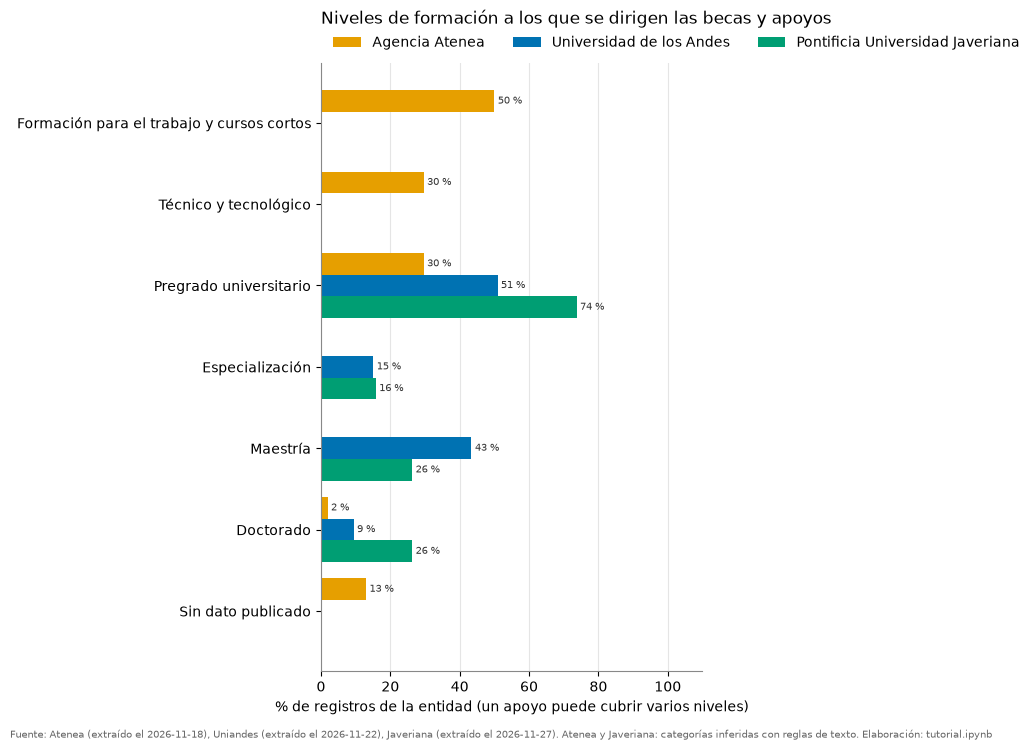

In [20]:
grafico_barras(nivel, "Niveles de formación a los que se dirigen las becas y apoyos",
               "% de registros de la entidad (un apoyo puede cubrir varios niveles)", "nivel_por_entidad.png")

**Interpretación.** La entidad pública y las universidades atienden niveles distintos:

- **Atenea** se dirige a lo que sigue al colegio: formación para el trabajo y cursos cortos (50,0 % de sus convocatorias), técnico y tecnológico (29,6 %) y pregrado (29,6 %). Solo tiene una convocatoria de doctorado (1,9 %) y ninguna de especialización o maestría.
- **Las dos universidades** no apoyan cursos cortos ni estudios técnicos o tecnológicos: financian su pregrado (50,9 % en Uniandes, 73,7 % en la Javeriana) y su posgrado. Uniandes pesa más en maestría (43,4 %); la Javeriana reparte su posgrado entre maestría y doctorado (26,3 % cada uno).
- Las tres **coinciden sobre todo en el pregrado universitario** (en doctorado, Atenea tiene una sola convocatoria). Para un curso, un técnico o una tecnología, la opción es Atenea; para un posgrado, las universidades.

En Atenea, el 13,0 % de las convocatorias no dice el nivel en su descripción.

Ahora, ¿con qué instrumento financia cada entidad esos niveles?

### 5.2 Instrumento financiero

¿Qué tipo de ayuda ofrece cada entidad? Las categorías son comunes a las tres: beca o subsidio de matrícula, descuento, crédito (condonable, con pago contingente o sin condonación), apoyo de sostenimiento y formación sin costo.

In [21]:
instrumento = porcentaje_por_categoria(becas_apoyos, "instrumento", ORDEN_INSTRUMENTO)
instrumento.to_csv("results/tabla_instrumento.csv", encoding="utf-8-sig")
instrumento

entidad,Agencia Atenea,Universidad de los Andes,Pontificia Universidad Javeriana
instrumento,,,
Beca o subsidio de matrícula,31.5,62.3,84.2
Descuento,0.0,7.5,0.0
Crédito,0.0,18.9,0.0
Crédito condonable,13.0,9.4,15.8
Crédito con pago contingente,3.7,0.0,0.0
Apoyo de sostenimiento,22.2,1.9,0.0
Formación sin costo,7.4,0.0,0.0
Sin dato publicado,42.6,0.0,0.0
Registros (n),54.0,53.0,19.0


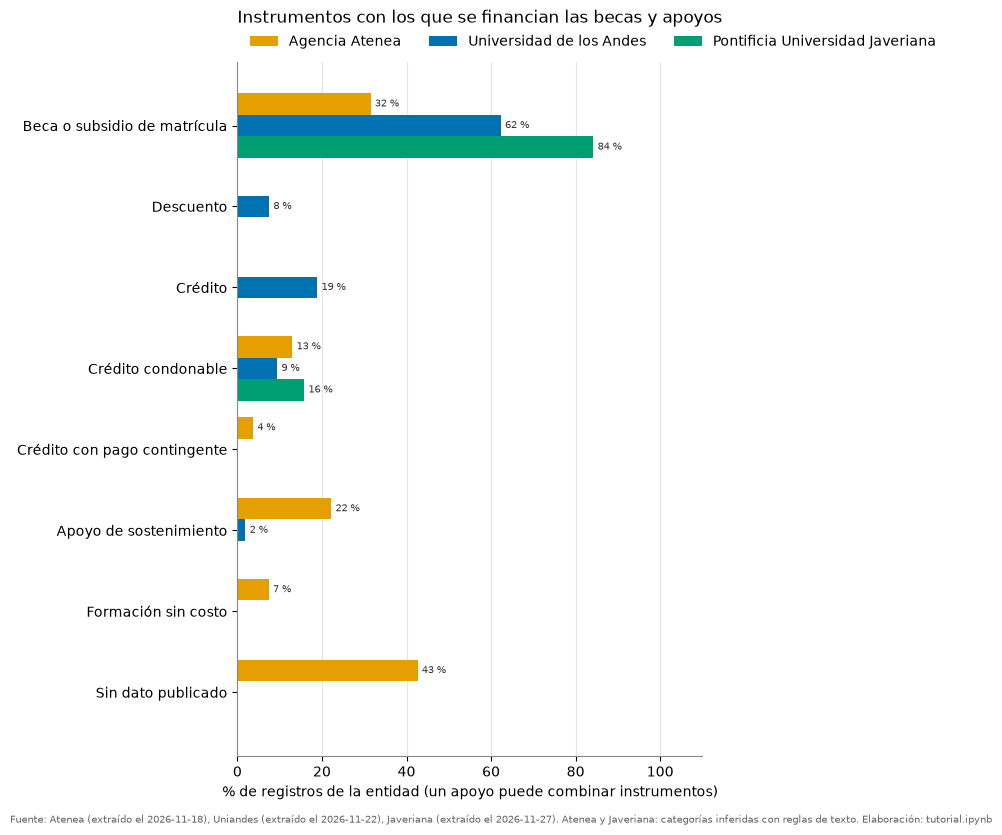

In [22]:
grafico_barras(instrumento, "Instrumentos con los que se financian las becas y apoyos",
               "% de registros de la entidad (un apoyo puede combinar instrumentos)", "instrumento_por_entidad.png")

**Interpretación.** Las tres usan sobre todo becas que pagan parte de la matrícula, pero cada una las combina distinto:

- **Atenea** es la única que paga también **sostenimiento** (22,2 % de sus convocatorias) y que da cursos sin costo (7,4 %). Usa créditos condonables (13,0 %) y con pago contingente al ingreso (3,7 %). El 42,6 % de sus convocatorias no dice el instrumento: son sobre todo cursos de Talento Capital y Todos a la U.
- **Uniandes** combina becas (62,3 %) con créditos que se pagan (18,9 %), créditos condonables (9,4 %) y descuentos (7,5 %).
- **La Javeriana** usa casi solo becas (84,2 %) y créditos condonables en posgrado (15,8 %); no ofrece créditos que se pagan ni sostenimiento en estas páginas.

### 5.3 ¿Qué parte de la matrícula cubren?

El instrumento dice cómo se financia un apoyo; el porcentaje dice cuánto de la matrícula cubre. Primero vemos cuántos registros publican un porcentaje y en qué forma (valor fijo, tope o rango):

In [23]:
resumen_porcentaje = becas_apoyos.groupby("entidad").agg(
    registros=("nombre", "size"),
    publican_porcentaje=("porcentaje_max", "count"),
    mediana_del_maximo=("porcentaje_max", "median"),
    llegan_a_90_o_mas=("porcentaje_max", lambda p: int((p >= 90).sum())),
    llegan_a_100=("porcentaje_max", lambda p: int((p == 100).sum())),
).reindex(ENTIDADES)
resumen_porcentaje.join(pd.crosstab(becas_apoyos["entidad"], becas_apoyos["forma_porcentaje"]))

,registros,publican_porcentaje,mediana_del_maximo,llegan_a_90_o_mas,llegan_a_100,exacto,hasta,rango
entidad,,,,,,,,
Agencia Atenea,54,3,100.0,3,3,3,0,0
Universidad de los Andes,53,45,90.0,23,7,12,28,5
Pontificia Universidad Javeriana,19,14,65.0,3,3,13,0,1


Atenea casi nunca publica un porcentaje, así que el detalle se compara entre las dos universidades: el máximo que puede cubrir cada apoyo, por nivel de formación.

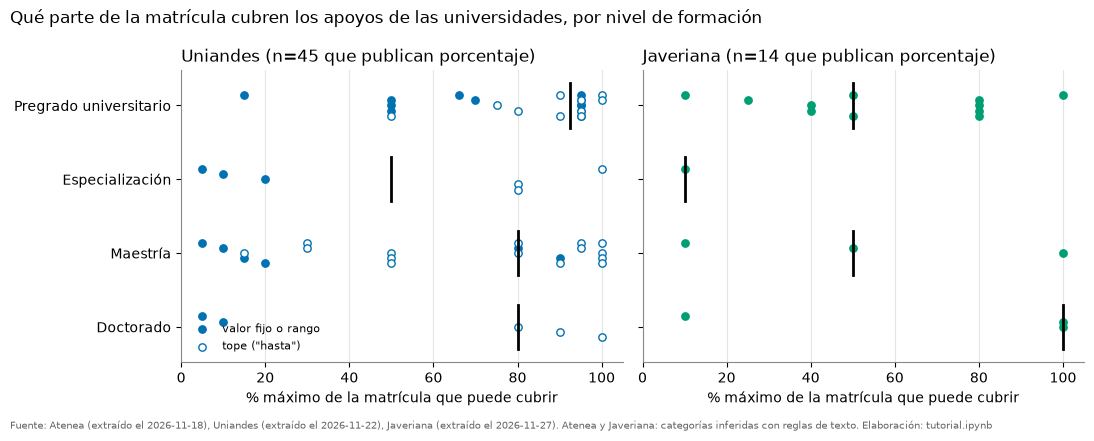

apoyos  minimo  \
Uniandes  Instrumento        Beca o subsidio de matrícula      28    15.0   
                             Descuento                          4     5.0   
                             Crédito                            9    75.0   
                             Crédito condonable                 4    50.0   
          Nivel de formación Pregrado universitario            22    15.0   
                             Especialización                    6     5.0   
                             Maestría                          21     5.0   
                             Doctorado                          5     5.0   
Javeriana Instrumento        Beca o subsidio de matrícula      11    10.0   
                             Crédito condonable                 3    50.0   
          Nivel de formación Pregrado universitario            11    10.0   
                             Especialización                    1    10.0   
                             Maestría                           3    10.0   
                             Doctorado                          3    10.0   

                                                           mediana  maximo  
Uniandes  Instrumento        Beca o subsidio de matrícula     92.5   100.0  
                             Descuento                        12.5    20.0  
                             Crédito                          90.0   100.0  
                             Crédito condonable               85.0    90.0  
          Nivel de formación Pregrado universitario           92.5   100.0  
                             Especialización                  50.0   100.0  
                             Maestría                         80.0   100.0  
                             Doctorado                        80.0   100.0  
Javeriana Instrumento        Beca o subsidio de matrícula     50.0   100.0  
                             Crédito condonable              100.0   100.0  
          Nivel de formación Pregrado universitario           50.0   100.0  
                             Especialización                  10.0    10.0  
                             Maestría                         50.0   100.0  
                             Doctorado                       100.0   100.0

In [24]:
con_porcentaje = becas_apoyos[becas_apoyos["entidad"].isin(UNIVERSIDADES) & becas_apoyos["porcentaje_max"].notna()]
partes = {}
for entidad in UNIVERSIDADES:
    base = con_porcentaje[con_porcentaje["entidad"] == entidad]
    for columna, orden, etiqueta in [("instrumento", ORDEN_INSTRUMENTO, "Instrumento"),
                                     ("nivel_formacion", ORDEN_NIVEL, "Nivel de formación")]:
        largo = separar(base, columna)
        partes[(NOMBRE_CORTO[entidad], etiqueta)] = (
            largo.groupby(columna)["porcentaje_max"].agg(apoyos="count", minimo="min", mediana="median", maximo="max")
            .reindex([c for c in orden if c in set(largo[columna])]))
porcentaje = pd.concat(partes)
porcentaje.to_csv("results/tabla_porcentaje_matricula.csv", encoding="utf-8-sig")

# Un punto por apoyo; relleno = valor fijo o rango publicado, hueco = tope ("hasta"). La raya negra es la mediana.
figura, ejes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
niveles = [n for n in ORDEN_NIVEL if n in set(separar(con_porcentaje, "nivel_formacion")["nivel_formacion"])]
for eje, entidad in zip(ejes, UNIVERSIDADES):
    largo = separar(con_porcentaje[con_porcentaje["entidad"] == entidad], "nivel_formacion")
    color = COLOR_ENTIDAD[entidad]
    for y, nivel_actual in enumerate(niveles):
        valores = largo[largo["nivel_formacion"] == nivel_actual].sort_values("porcentaje_max")
        if valores.empty:
            continue
        desplazamiento = [((k % 5) - 2) * 0.07 for k in range(len(valores))]  # separa puntos iguales (sin azar)
        es_tope = (valores["forma_porcentaje"] == "hasta").to_numpy()
        posiciones = [y + d for d in desplazamiento]
        eje.scatter(valores["porcentaje_max"][~es_tope], [p for p, t in zip(posiciones, es_tope) if not t],
                    color=color, s=28, label="valor fijo o rango" if y == 0 else None)
        eje.scatter(valores["porcentaje_max"][es_tope], [p for p, t in zip(posiciones, es_tope) if t],
                    facecolors="white", edgecolors=color, s=28, label="tope (\"hasta\")" if y == 0 else None)
        eje.plot([valores["porcentaje_max"].median()] * 2, [y - 0.3, y + 0.3], color="black", linewidth=2)
    eje.set_yticks(range(len(niveles)), niveles)
    eje.set_xlim(0, 105)
    eje.set_xlabel("% máximo de la matrícula que puede cubrir")
    eje.set_title(f"{NOMBRE_CORTO[entidad]} (n={int((con_porcentaje['entidad'] == entidad).sum())} que publican porcentaje)",
                  loc="left")
    eje.grid(axis="y", visible=False)
ejes[0].invert_yaxis()
ejes[0].legend(frameon=False, loc="lower left", fontsize=8)
figura.suptitle("Qué parte de la matrícula cubren los apoyos de las universidades, por nivel de formación",
                x=0.01, ha="left")
guardar_figura(figura, "porcentaje_matricula.png")
porcentaje

**Interpretación.** El porcentaje muestra qué tan completa es la ayuda:

- **Uniandes** publica el porcentaje en 45 de sus 53 apoyos y suele cubrir gran parte de la matrícula: la mediana del máximo es 90 %, 23 apoyos llegan al 90 % o más y 7 al 100 %. Pero 28 de los 45 son topes ("hasta el 90 %"): cuánto recibe cada estudiante depende de su necesidad económica y del presupuesto. Por nivel, el pregrado cubre más (mediana de 92,5 %) que la maestría y el doctorado (80 %) y la especialización (50 %).
- **La Javeriana** publica el porcentaje en 14 de sus 19 becas, casi siempre como un valor fijo, y cubre menos: la mediana es 65 %. En pregrado la mediana es 50 % (entre 10 % y 100 %); sus créditos condonables de doctorado cubren el 100 %.
- **Atenea** solo dice el porcentaje en 3 convocatorias, y en las tres es el 100 % de la matrícula. En las demás describe la ayuda como "el valor de la matrícula" o en salarios mínimos.
- Entre las privadas hay diferencias: **lo que cubre una universidad no es lo que cubren todas**. En pregrado, Uniandes cubre una parte mayor de la matrícula que la Javeriana.

### 5.4 Nivel e instrumento juntos

Para ver en qué se especializa cada entidad, cruzamos las dos variables: cuántos registros combinan cada nivel con cada instrumento. Solo entran los registros que publican ambos.

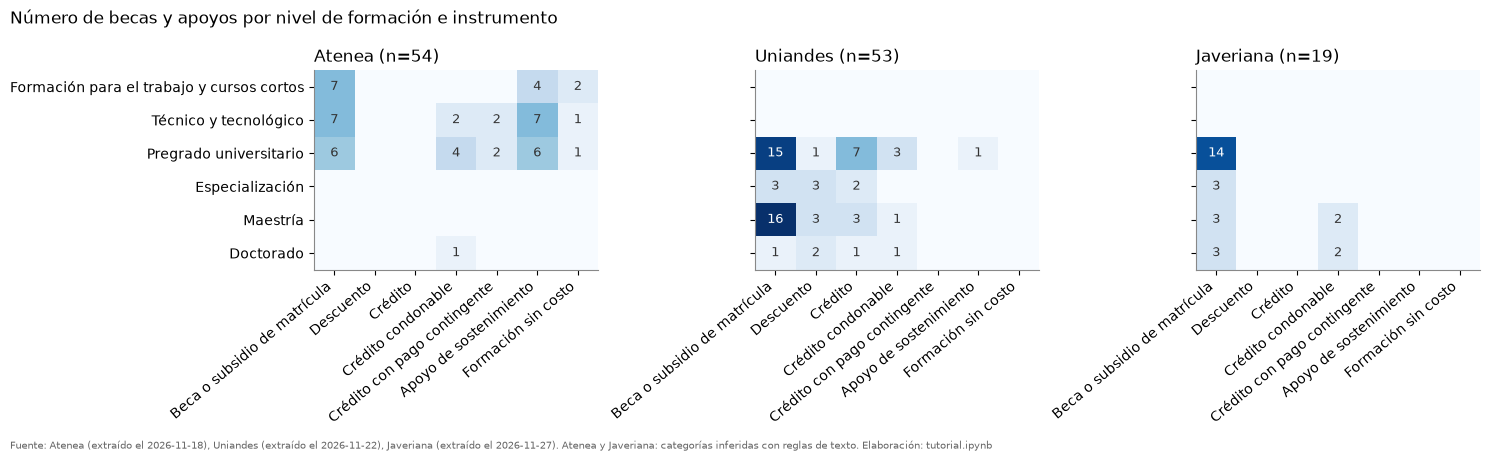

In [25]:
cruce = separar(separar(becas_apoyos, "nivel_formacion"), "instrumento")
cruce = cruce[(cruce["nivel_formacion"] != SIN_DATO) & (cruce["instrumento"] != SIN_DATO)]
nivel_instrumento = pd.crosstab([cruce["entidad"], cruce["nivel_formacion"]], cruce["instrumento"])
nivel_instrumento.to_csv("results/tabla_nivel_instrumento.csv", encoding="utf-8-sig")

figura, ejes = plt.subplots(1, len(ENTIDADES), figsize=(15, 4.4), sharey=True)
filas = [n for n in ORDEN_NIVEL if n in set(cruce["nivel_formacion"])]
columnas = [i for i in ORDEN_INSTRUMENTO if i in set(cruce["instrumento"])]
maximo = nivel_instrumento.to_numpy().max()
for eje, entidad in zip(ejes, ENTIDADES):
    matriz = nivel_instrumento.loc[entidad].reindex(index=filas, columns=columnas, fill_value=0)
    eje.imshow(matriz, cmap="Blues", vmin=0, vmax=maximo, aspect="auto")
    for i in range(len(filas)):
        for j in range(len(columnas)):
            valor = matriz.iloc[i, j]
            if valor > 0:
                eje.text(j, i, str(valor), ha="center", va="center", fontsize=9,
                         color="white" if valor > maximo / 2 else "#333333")
    eje.set_xticks(range(len(columnas)), columnas, rotation=40, ha="right")
    eje.set_yticks(range(len(filas)), filas)
    eje.set_title(f"{NOMBRE_CORTO[entidad]} (n={int((becas_apoyos['entidad'] == entidad).sum())})", loc="left")
    eje.grid(False)
figura.suptitle("Número de becas y apoyos por nivel de formación e instrumento", x=0.01, ha="left")
guardar_figura(figura, "nivel_instrumento.png")

**Interpretación.** El cruce muestra cómo se complementan:

- **Atenea** combina en los tres niveles después del colegio (cursos, técnico y tecnológico, pregrado) el pago de la matrícula con apoyo de sostenimiento. Sus créditos aparecen en técnico, tecnológico y pregrado.
- **Uniandes** financia el pregrado con becas (15 apoyos) y créditos (7), y la maestría sobre todo con becas (16).
- **La Javeriana** financia el pregrado solo con becas (14) y el posgrado con becas y créditos condonables.

Queda la última variable de la pregunta: el área de conocimiento.

### 5.5 Área de conocimiento

Para comparar las tres fuentes usamos las áreas de conocimiento del SNIES (sección 3). "Cualquier área" agrupa los apoyos que no restringen el área: sirven para los programas que ofrezca la institución.

entidad,Agencia Atenea,Universidad de los Andes,Pontificia Universidad Javeriana
area_conocimiento,,,
Bellas artes,0.0,54.7,5.3
Ciencias de la educación,0.0,49.1,5.3
Ciencias de la salud,0.0,37.7,0.0
Ciencias sociales y humanas,7.4,69.8,0.0
"Economía, administración, contaduría y afines",0.0,54.7,0.0
"Ingeniería, arquitectura, urbanismo y afines",13.0,58.5,0.0
Matemáticas y ciencias naturales,0.0,50.9,5.3
"Servicios (turismo, belleza y otros)",7.4,0.0,0.0
Cualquier área,75.9,0.0,84.2


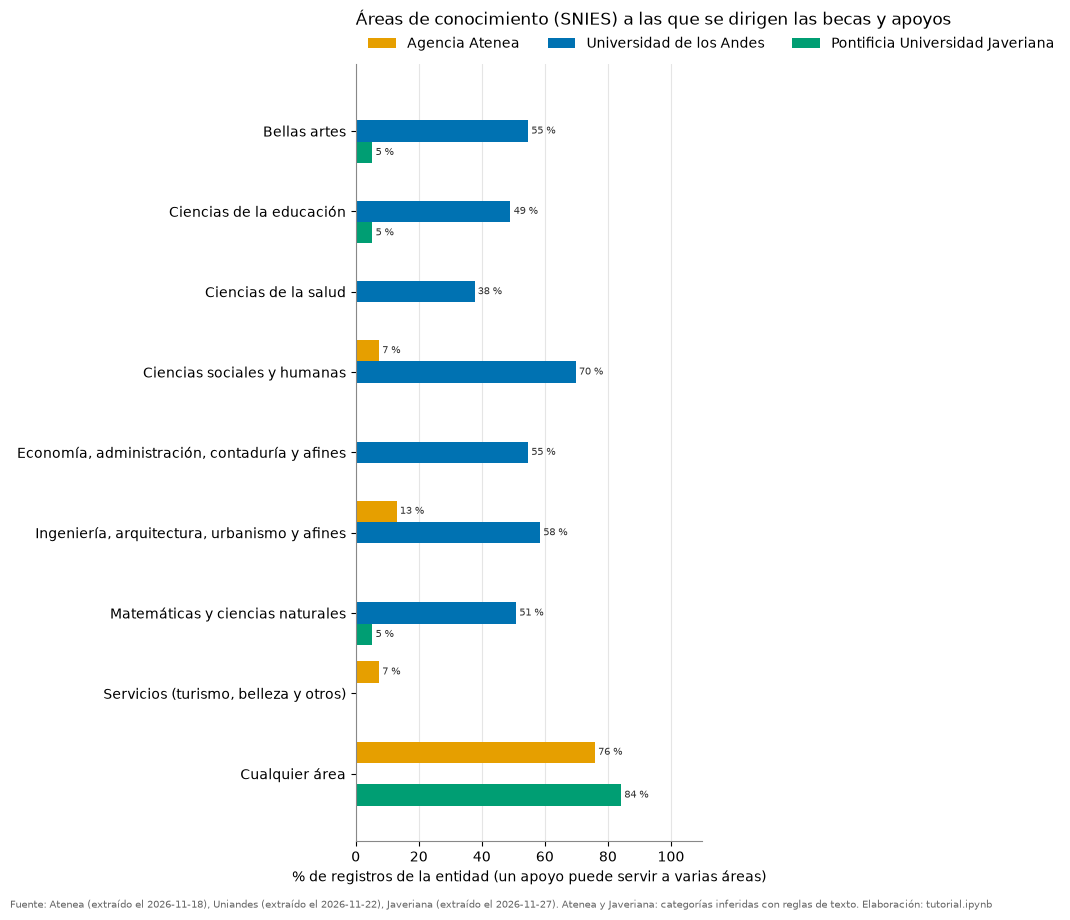

In [26]:
# "Cualquier área" es una categoría aparte: el apoyo no restringe el área y sirve para los programas
# que ofrezca la institución (no sabemos si la Javeriana o las aliadas de Atenea tienen programas en todas
# las áreas del SNIES, así que no se reparte entre ellas).
ORDEN_AREA = scrapers.AREAS_SNIES + ["Servicios (turismo, belleza y otros)", scrapers.CUALQUIER_AREA]
largo_area = separar(becas_apoyos, "area_conocimiento")
area = porcentaje_por_categoria(becas_apoyos, "area_conocimiento", ORDEN_AREA)
area.to_csv("results/tabla_area.csv", encoding="utf-8-sig")
display(area)
grafico_barras(area, "Áreas de conocimiento (SNIES) a las que se dirigen las becas y apoyos",
               "% de registros de la entidad (un apoyo puede servir a varias áreas)", "area_por_entidad.png")

El cruce de área y nivel responde la pregunta de un joven concreto: "quiero estudiar tal área a tal nivel, ¿dónde busco?". Cada casilla cuenta los registros de la entidad que sirven para esa combinación:

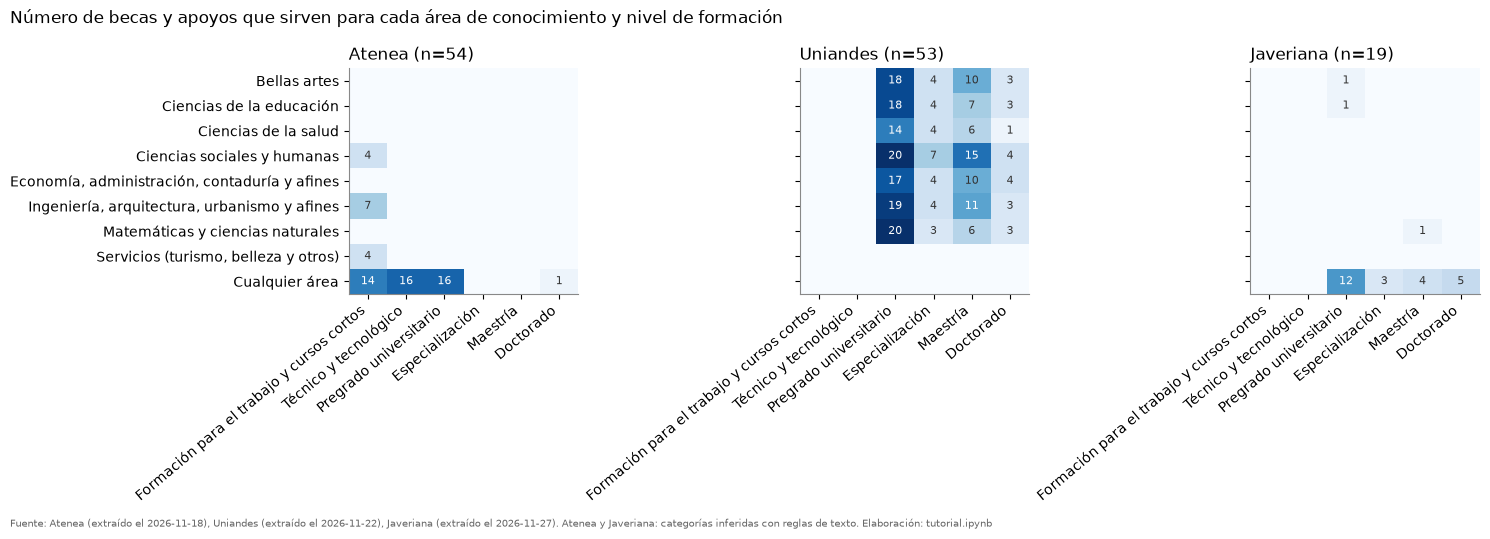

In [27]:
# Área × nivel: cuántos registros de cada entidad sirven para cada combinación. Es la vista que
# responde "quiero estudiar tal área a tal nivel: ¿dónde busco?".
area_nivel_largo = separar(largo_area[largo_area["area_conocimiento"] != SIN_DATO], "nivel_formacion")
area_nivel_largo = area_nivel_largo[area_nivel_largo["nivel_formacion"] != SIN_DATO]
area_nivel = pd.crosstab([area_nivel_largo["entidad"], area_nivel_largo["area_conocimiento"]],
                         area_nivel_largo["nivel_formacion"])
area_nivel.to_csv("results/tabla_area_nivel.csv", encoding="utf-8-sig")

filas = [a for a in ORDEN_AREA if a in set(area_nivel_largo["area_conocimiento"])]
columnas = [n for n in ORDEN_NIVEL if n in set(area_nivel_largo["nivel_formacion"])]
maximo = area_nivel.to_numpy().max()
figura, ejes = plt.subplots(1, len(ENTIDADES), figsize=(15, 5.2), sharey=True)
for eje, entidad in zip(ejes, ENTIDADES):
    matriz = area_nivel.loc[entidad].reindex(index=filas, columns=columnas, fill_value=0)
    eje.imshow(matriz, cmap="Blues", vmin=0, vmax=maximo, aspect="auto")
    for i in range(len(filas)):
        for j in range(len(columnas)):
            valor = matriz.iloc[i, j]
            if valor > 0:
                eje.text(j, i, str(valor), ha="center", va="center", fontsize=8,
                         color="white" if valor > maximo / 2 else "#333333")
    eje.set_xticks(range(len(columnas)), columnas, rotation=40, ha="right")
    eje.set_yticks(range(len(filas)), filas)
    eje.set_title(f"{NOMBRE_CORTO[entidad]} (n={int((becas_apoyos['entidad'] == entidad).sum())})", loc="left")
    eje.grid(False)
figura.suptitle("Número de becas y apoyos que sirven para cada área de conocimiento y nivel de formación",
                x=0.01, ha="left")
guardar_figura(figura, "area_nivel.png")

En Uniandes, que publica los programas de cada apoyo, vemos además a cuántos programas aplica cada apoyo y cuántos apoyos tiene disponibles cada programa, según su nivel (el nivel de cada programa sale del catálogo de la universidad):

In [28]:
uniandes = becas_apoyos[becas_apoyos["entidad"] == "Universidad de los Andes"]
alcance = pd.cut(uniandes["n_programas"], bins=[0, 1, 10, 50, 1000],
                 labels=["1 programa", "2 a 10 programas", "11 a 50 programas", "Más de 50 programas"])
alcance = alcance.value_counts().sort_index().rename("apoyos").to_frame()
alcance.to_csv("results/tabla_alcance_programas.csv", encoding="utf-8-sig")
display(alcance)

apoyos_por_programa = separar(uniandes, "programas")["programas"].value_counts().rename("apoyos")
programas = scrapers.catalogo_programas_uniandes().set_index("programa").join(apoyos_por_programa).fillna({"apoyos": 0})
programas = (programas.groupby("nivel")["apoyos"].agg(programas="count", minimo="min", mediana="median", maximo="max")
             .reindex([n for n in ORDEN_NIVEL if n in set(programas["nivel"])]))
programas.to_csv("results/tabla_apoyos_por_programa.csv", encoding="utf-8-sig")
programas

,apoyos
n_programas,
1 programa,9
2 a 10 programas,14
11 a 50 programas,25
Más de 50 programas,5


,programas,minimo,mediana,maximo
nivel,,,,
Pregrado universitario,44,14,17.0,18
Especialización,41,2,3.0,5
Maestría,92,3,6.0,8
Doctorado,17,3,4.0,6


**Interpretación.** El área separa a las entidades por la forma en que dirigen sus apoyos, no por el área que prefieren:

- **Atenea y la Javeriana casi nunca restringen el área**: el 75,9 % de las convocatorias de Atenea y el 84,2 % de las becas de la Javeriana sirven para cualquier programa (de las instituciones aliadas de Atenea o de la propia Javeriana). Las excepciones de Atenea son cursos cortos de un sector: tecnologías digitales y construcción (13,0 % en ingeniería y afines), idiomas (7,4 %) y servicios como turismo o belleza (7,4 %). Las de la Javeriana son tres: música, licenciaturas y maestrías de la Facultad de Ciencias.
- **Uniandes dirige cada apoyo a facultades concretas**, pero entre muchas: cada área tiene disponible entre el 37,7 % (ciencias de la salud) y el 69,8 % (ciencias sociales y humanas) de sus apoyos. No tiene programas de agronomía o veterinaria. Solo 9 de sus 53 apoyos aplican a un único programa, y un programa de pregrado tiene una mediana de 17 apoyos disponibles, frente a 6 en maestría, 4 en doctorado y 3 en especialización.
- Para un joven, esto significa que **el área casi nunca lo excluye**: lo que define sus opciones es el nivel y, en las universidades, ser admitido en el programa.

## 6. App en Streamlit

El análisis responde la pregunta en general; la app la responde para cada joven. La tabla limpia de la sección 4 y los hallazgos de la sección 9 alimentan una página que lo guía según lo que quiere estudiar.

**Qué hace `app.py`**

- **Portada con los hallazgos** del tutorial (`results/hallazgos.csv`, sección 9), para orientar la búsqueda antes de filtrar.
- **Búsqueda guiada:** el joven elige su nivel y su área (SNIES); opcionalmente, entidad, tipo de ayuda, tipo de estudiante y porcentaje mínimo de la matrícula. Los resultados se pueden ordenar por fecha de cierre, por porcentaje de la matrícula o por tipo de ayuda.
- **Tarjetas completas:** cada apoyo muestra a quién va dirigido, qué cubre, la descripción completa, el tipo de estudiante, las fechas y el enlace oficial. Las convocatorias de Atenea advierten que solo aplican en sus instituciones aliadas.
- **Oculta las convocatorias vencidas** (estado "cerrada", sección 4.6) y muestra las líneas de Atenea que suelen volver a abrir (sección 8).
- Lee solo archivos de `results/` que genera este notebook: la app y el tutorial muestran los mismos datos. Para datos más recientes se pone `ACTUALIZAR_DATOS = True` en la sección 1, se ejecuta todo el notebook (unos 10 minutos, con internet) y se vuelve a cargar la app.

**Cómo correrla.** Desde una terminal ubicada en la carpeta del proyecto, con el entorno virtual activado:

```
streamlit run app.py
```

En Windows, sin activar el entorno: `.venv\Scripts\streamlit.exe run app.py`. La app se abre en http://localhost:8501 y se cierra con Ctrl+C en la terminal. Esta sección no ejecuta la app, porque Streamlit es un servidor web y bloquearía el notebook.

## 7. Limitaciones

Los resultados anteriores responden la pregunta para unas fechas, unas fuentes y unas reglas de clasificación concretas.
Estas son las limitaciones que hay que tener en cuenta al leerlos.

- **Clasificación inferida en Atenea.** En Uniandes, nivel, instrumento y programas los publica la universidad. En Atenea se deducen con reglas de palabras clave sobre el inicio de la descripción: el 13,0 % de sus convocatorias queda sin nivel y el 42,6 % sin instrumento, sobre todo cursos cortos que no dicen cómo se financian. Las reglas también pueden equivocarse con redacciones inesperadas; por ejemplo, el nombre de una institución ("Universitaria Agustiniana") cuenta como pregrado universitario. Las reglas y una muestra de resultados están en la sección 3 para que se puedan revisar.
- **Clasificación inferida en la Javeriana.** El nivel sale de la página (pregrado o posgrado); en posgrado, si la beca no dice el nivel, se asumen los tres. El instrumento es beca salvo que el nombre o la sección digan crédito condonable, y el área solo se asigna en tres becas cuyo nombre la indica.
- **Área de conocimiento.** Las facultades de Uniandes se traducen a las áreas del SNIES por facultad, no por programa (por ejemplo, Arquitectura y Diseño cuenta en ingeniería y en bellas artes). "Cualquier área" significa que el apoyo no restringe el área, no que la institución tenga programas en todas las áreas.
- **Instituciones aliadas de Atenea.** Atenea no financia estudios en cualquier institución, sino en sus aliadas, y la lista cambia según la convocatoria. Esa lista está en los textos y PDF de cada convocatoria y no se extrajo.
- **Unidades distintas.** En las universidades un registro es un apoyo del catálogo, que puede abrir convocatorias cada semestre. En Atenea un registro es una convocatoria: incluye todas las publicadas en el portal, vigentes y pasadas, así que los programas con muchas convocatorias (Todos a la U, Talento Capital) pesan más en sus porcentajes. La sección 8 repite la medición por línea de apoyo, que corrige este peso; la asignación de cada convocatoria a su línea es inferida.
- **Porcentaje de la matrícula.** Muchos porcentajes de Uniandes son topes ("hasta el 90 %"): el valor que recibe cada estudiante puede ser menor. Atenea casi nunca publica un porcentaje, así que la comparación del porcentaje solo es posible entre las dos universidades.
- **Número de apoyos, no recursos.** La concentración se mide por número de becas y apoyos, no por montos, cupos ni beneficiarios, que las fuentes no publican de forma estructurada.
- **Área.** Atenea casi nunca declara un área. En Uniandes, la "Decanatura de Estudiantes" aparece como facultad porque así la publica el catálogo, aunque es una unidad administrativa.
- **Tres fechas de extracción.** Atenea se extrajo el 18 de noviembre de 2026, Uniandes el 22 y la Javeriana el 27. El estado de las convocatorias cambia cada día; con `ACTUALIZAR_DATOS = True` se obtiene una foto nueva de las tres fuentes el mismo día.
- **Fuentes.** SICORE (Atenea) exige usuario y contraseña, así que no se incluyen sus datos. En Uniandes usamos el servicio JSON del buscador, que no tiene documentación pública que conozcamos y depende de una clave de acceso del propio buscador. El 26 de noviembre de 2026 dejó de responder (HTTP 500, "Error durante la autenticación"). Por eso, si el catálogo no está disponible (por ejemplo, con `ACTUALIZAR_DATOS = True`), la descarga reutiliza el último catálogo bueno y solo vuelve a bajar las fichas públicas: las fechas se mantienen al día, pero no se detectarían apoyos nuevos. En la Javeriana no se incluyen sus descuentos ni sus becas de posgrado para estudiantes, que están en páginas con otra estructura, ni sus apoyos de movilidad. Son tres entidades, no toda la oferta de Bogotá: faltan las universidades públicas (cuyos apoyos son sobre todo de bienestar: alimentación, transporte y alojamiento), otras privadas, el SENA, ICETEX directo y fundaciones.
- **Cambios en las páginas.** Los extractores dependen de la estructura del HTML, del JSON, de los PDF y de las URL de cada sitio. Si una entidad cambia su diseño, hay que ajustar las funciones de `utils/scrapers.py`.
- **Sin causalidad.** El análisis es descriptivo: compara lo que se publica y no dice nada sobre el efecto de los apoyos ni sobre quién los recibe.

## 8. Uso de IA para ir más allá de la metodología

El resultado de las secciones 5 y 6 tiene un problema práctico: la lista de convocatorias abiertas caduca en días, y el tutorial trabaja con una foto fija para ser replicable. Le pedimos a una IA (Claude) ideas para que el tutorial, por sí solo, siga sirviéndole a un joven después de la foto.

### Prompt

> **Contexto:** nuestro tutorial de becas y apoyos educativos (Atenea y Uniandes) debe ser replicable, así que trabaja con una foto fija de noviembre de 2026. La app de Streamlit es útil para los jóvenes solo si está al día, y el tutorial no puede actualizarse siempre sin dejar de ser replicable.
>
> **Metodología actual:** el tutorial termina en tablas de concentración por nivel, instrumento y área, y en una lista de convocatorias abiertas o próximas a la fecha de la foto, que caduca en días. Tenemos además las convocatorias pasadas de Atenea (desde 2022, muchas son ediciones de una misma línea) y las fechas que publica Uniandes para sus apoyos permanentes.
>
> **Objetivo:** que el resultado del tutorial, por sí solo y sin usar la app, le sirva durante meses a un joven que busca un apoyo para estudiar: qué buscar, dónde y cuándo.
>
> **Restricciones:** replicable y sin internet; sin datos inventados (lo deducido se marca como inferido); solo con los datos que ya tenemos y con pandas y matplotlib; debe ayudar a responder la pregunta del tutorial, no agregar un análisis aparte.
>
> Propón entre 3 y 5 ideas, de la más útil a la menos útil. Para cada una: qué cambiarías, cómo la construirías con nuestros datos, por qué seguiría sirviendo cuando las convocatorias de la foto ya hayan cerrado, y sus riesgos. Al final, di cuál implementarías primero.

### Respuesta de la IA

> Propongo dejar de mostrar como resultado las convocatorias, que caducan, y mostrar las **líneas de apoyo**, que se repiten. Una convocatoria cierra en días; la línea que la abre vuelve a abrir. Sus datos ya lo muestran: las 54 convocatorias de Atenea son, en su mayoría, ediciones de unas 11 líneas. Talento Capital tiene 10 ediciones, Jóvenes a la E más de 15 y el Fondo Técnica y Tecnológica 5. Los 52 apoyos de Uniandes ya son líneas permanentes.
>
> **1. Ficha por línea de apoyo (la más útil)**
> - *Qué cambiaría:* agregaría una tabla final con una fila por línea en lugar de una por convocatoria. Columnas: entidad, niveles de formación, instrumentos, porcentaje de la matrícula que cubre, número de ediciones, primera y última edición, y el enlace a la sección oficial donde se publica.
> - *Cómo construirla:* una regla explícita sobre el nombre asigna cada convocatoria de Atenea a su línea (por ejemplo, "talento capital", "técnica y tecnológica", "jóvenes a la e … trabajo"). Después, `groupby("linea")` reúne niveles e instrumentos y cuenta las ediciones. En Uniandes cada apoyo es su propia fila.
> - *Por qué seguiría sirviendo:* cuando cierren las convocatorias de la foto, las líneas seguirán existiendo, y el joven sabrá cuáles le aplican. Además, la fecha de la última edición distingue las líneas activas de las que ya no se ofrecen. Todos a la U no abre desde 2024 y Jóvenes a la U desde 2023; las reemplazaron Talento Capital y Jóvenes a la E.
> - *Riesgos:* la regla de agrupación es inferida. Algunas convocatorias de Jóvenes a la E no dicen en su nombre a qué línea pertenecen, y Atenea no publica una página fija por línea, así que el enlace sería el de la sección de convocatorias o el de la última edición.
>
> **2. Calendario histórico de aperturas**
> - *Qué cambiaría:* por cada línea, los meses en que abrió y la mediana de días de inscripción.
> - *Cómo construirlo:* con `fecha_apertura.dt.month` y `dias_ventana`, que ya están en la tabla, agrupados por línea. Un gráfico de línea por mes (enero a diciembre) mostraría el patrón de un vistazo.
> - *Por qué seguiría sirviendo:* dice cuándo estar atento, que es justo lo que la foto no puede dar. En Atenea, 32 de las 52 convocatorias con fecha abrieron en mayo-junio o noviembre-diciembre. Los Fondos Técnica y Tecnológica y Alianza abrieron en mayo y en diciembre, y las inscripciones de Jóvenes a la E duran poco (mediana de 7 a 10 días), así que conviene tener los documentos listos antes. En Uniandes, 30 de los 33 apoyos con fecha cierran en noviembre o diciembre.
> - *Riesgos:* describe lo que pasó entre 2022 y 2026; no predice la próxima apertura. Algunas líneas tienen solo 2 o 3 ediciones. Debe decir "suele abrir (inferido)", nunca "abrirá".
>
> **3. Guía por perfil en las conclusiones**
> - *Qué cambiaría:* una tabla de decisión con filas como "bachiller que quiere estudiar técnico, tecnológico o profesional", "admitido a pregrado en Uniandes", "interesado en posgrado" o "busca un curso corto para trabajar". Columnas: líneas que le aplican, qué le pueden cubrir y cuándo suelen abrir.
> - *Cómo construirla:* filtrando la ficha de la idea 1 por nivel e instrumento y tomando los meses de la idea 2. No requiere datos nuevos.
> - *Por qué seguiría sirviendo:* convierte el análisis de concentración en una respuesta práctica a la pregunta del tutorial ("en qué entidad y con qué instrumento tengo más opciones"), y no depende de qué esté abierto hoy.
> - *Riesgos:* simplifica. Un joven puede encajar en varios perfiles, y los requisitos exactos cambian de una edición a otra, así que la guía debe remitir siempre al enlace oficial.
>
> **4. Requisitos recurrentes por línea (la menos útil con los datos actuales)**
> - *Qué cambiaría:* para cada línea, los requisitos que se repiten entre ediciones (colegio de Bogotá, Saber 11, Sisbén o estrato, edad, estar admitido), para que el joven pueda prepararse.
> - *Cómo construirlo:* con las reglas de palabras clave que ya usan para los requisitos, aplicadas por línea.
> - *Por qué seguiría sirviendo:* los requisitos de una línea cambian poco entre ediciones.
> - *Riesgos:* en Atenea solo 5 convocatorias tienen requisitos extraídos, porque solo se descargaron los PDF de las vigentes. Con tan pocos datos, la mayoría de las líneas quedaría vacía. Habría que ampliar la descarga, y eso sale de la restricción de usar solo los datos que ya tienen.
>
> **Cuál implementaría primero:** la ficha por línea de apoyo (idea 1). Es la base de las otras dos: el calendario se calcula por línea, y la guía por perfil filtra esa ficha. Además, responde directamente la pregunta del tutorial con una unidad que no caduca.

### Qué va más allá de lo recomendado

Las recomendaciones de la evaluación de la propuesta (sección 0) piden, sobre todo, identificar las convocatorias vencidas y validar fechas y enlaces (recomendación 4). Seguirlas deja una lista de lo vigente en la fecha de la foto. La IA propone tres cosas que van más allá:

- **Usar las convocatorias vencidas como información, no solo descartarlas.** Las ediciones pasadas dicen qué líneas existen, qué niveles e instrumentos han cubierto y si siguen activas.
- **Cambiar la unidad de análisis** de la convocatoria a la línea de apoyo. Eso corrige una limitación de la sección 7: en Atenea, las líneas con muchas ediciones pesaban más en los porcentajes.
- **Un resultado que sirve sin la app y sin actualizar los datos:** una guía por nivel de formación que dice qué líneas buscar y dónde, aunque las convocatorias de la foto ya hayan cerrado.

### Implementación y efecto

Implementamos las ideas 1 y 3. Las reglas que asignan cada convocatoria de Atenea a su línea están en `scrapers.LINEAS_ATENEA` (inferido): se buscan en el nombre, y gana la primera que coincide. Las convocatorias que no coinciden con ninguna regla son únicas, y su línea es su propio nombre. En las universidades (Uniandes y Javeriana), cada apoyo del catálogo ya es una línea permanente.

`scrapers.ficha_por_linea` reúne las ediciones de cada línea: une sus niveles, instrumentos y áreas, toma el mayor porcentaje de la matrícula publicado, la primera y la última apertura, y el enlace de la edición más reciente. La columna `situacion` dice cómo estaba la línea en la fecha de la foto:

- *abierta o próxima en la foto:* tiene al menos una convocatoria abierta o próxima;
- *abrió en los últimos 12 meses:* sin convocatoria abierta, pero con una edición en el último año;
- *sin convocatorias desde AAAA (posiblemente terminada)* (inferido): su última edición tiene más de 12 meses;
- *sin fecha publicada:* la línea no publica fechas;
- *en el catálogo, sin convocatoria abierta:* apoyo de una universidad sin fechas abiertas o próximas en la foto.

In [29]:
lineas = scrapers.ficha_por_linea(becas_apoyos, ORDEN_NIVEL, ORDEN_INSTRUMENTO)
lineas.to_csv("results/tabla_lineas_apoyo.csv", index=False, encoding="utf-8-sig")

print("Registros por entidad:", becas_apoyos["entidad"].value_counts().to_dict())
print("Líneas de apoyo por entidad:", lineas["entidad"].value_counts().to_dict())
display(lineas.groupby(["entidad", "situacion"]).size().rename("líneas").to_frame())

# Las líneas de Atenea, de la más reciente a la más antigua
(lineas[lineas["entidad"] == "Agencia Atenea"]
 .sort_values("ultima_apertura", ascending=False)
 [["linea", "ediciones", "nivel_formacion", "instrumento", "primera_apertura", "ultima_apertura", "situacion"]])

Registros por entidad: {'Agencia Atenea': 54, 'Universidad de los Andes': 53, 'Pontificia Universidad Javeriana': 19}
Líneas de apoyo por entidad: {'Universidad de los Andes': 53, 'Pontificia Universidad Javeriana': 19, 'Agencia Atenea': 14}


líneas
entidad                          situacion                                                    
Agencia Atenea                   abierta o próxima en la foto                                6
                                 abrió en los últimos 12 meses                               4
                                 sin convocatorias desde 2022 (posiblemente terminada)       1
                                 sin convocatorias desde 2023 (posiblemente terminada)       1
                                 sin convocatorias desde 2024 (posiblemente terminada)       1
                                 sin fecha publicada                                         1
Pontificia Universidad Javeriana en el catálogo, sin convocatoria abierta                   19
Universidad de los Andes         abierta o próxima en la foto                               26
                                 en el catálogo, sin convocatoria abierta                   27

,linea,ediciones,nivel_formacion,instrumento,primera_apertura,ultima_apertura,situacion
2,Fondo Alianza Ciudad Educadora,3,Pregrado universitario,Crédito condonable; Apoyo de sostenimiento,2024-05-20 00:00:00,2026-12-14 08:00:00,abierta o próxima en la foto
3,Fondo Técnica y Tecnológica,5,Técnico y tecnológico; Pregrado universitario,Beca o subsidio de matrícula; Crédito condonable; Apoyo de sostenimiento,2024-05-20 00:00:00,2026-12-14 08:00:00,abierta o próxima en la foto
5,Jóvenes a la E: formación para el trabajo,5,Formación para el trabajo y cursos cortos,Beca o subsidio de matrícula,2025-07-09 00:00:00,2026-12-02 08:00:00,abierta o próxima en la foto
1,FEST (crédito con pago contingente),3,Técnico y tecnológico; Pregrado universitario,Crédito condonable; Crédito con pago contingente,2025-06-18 00:00:00,2026-11-17 17:00:00,abierta o próxima en la foto
6,Jóvenes a la E: instituciones privadas,6,Formación para el trabajo y cursos cortos; Técnico y tecnológico; Pregrado universitario,Beca o subsidio de matrícula; Apoyo de sostenimiento,2024-04-26 00:00:00,2026-11-12 17:00:00,abierta o próxima en la foto
7,Jóvenes a la E: instituciones públicas,6,Formación para el trabajo y cursos cortos; Técnico y tecnológico; Pregrado universitario,Beca o subsidio de matrícula; Apoyo de sostenimiento,2025-09-23 00:00:00,2026-11-07 12:00:00,abierta o próxima en la foto
8,Jóvenes a la E: talentos excepcionales,2,NaN,Beca o subsidio de matrícula,2025-11-11 00:00:00,2026-10-19 08:00:00,abrió en los últimos 12 meses
11,Talento Capital,10,Formación para el trabajo y cursos cortos,Formación sin costo,2024-06-24 00:00:00,2026-10-09 08:00:00,abrió en los últimos 12 meses
10,PROGRAMA BECAS UNIVERSIDAD LIBRE Y FUNDACIÓN UNIVERSIDAD AMÉRICA,1,Pregrado universitario,Beca o subsidio de matrícula; Formación sin costo,2026-07-11 12:00:00,2026-07-11 12:00:00,abrió en los últimos 12 meses
4,Fondo para Víctimas del Conflicto,2,NaN,NaN,2025-06-05 00:00:00,2025-12-04 00:00:00,abrió en los últimos 12 meses


**Lectura de la ficha.** Las 54 convocatorias de Atenea son ediciones de 14 líneas: 11 que se repiten (Talento Capital tiene 10 ediciones) y 3 convocatorias únicas. De las 14, 6 tenían una convocatoria abierta o próxima en la foto y 4 abrieron en los 12 meses anteriores: son líneas que un joven puede esperar que vuelvan a abrir (inferido). Tres no abren desde 2022, 2023 o 2024 (Todos a la U, Jóvenes a la U y un curso de habilidades digitales), y la del proyecto Roberto Zarama no publica fechas. En las universidades, los 53 apoyos de Uniandes y las 19 becas de la Javeriana siguen en su catálogo; 26 de Uniandes tenían fechas abiertas o próximas en la foto (la Javeriana no publica fechas).

**Efecto en los resultados.** Medir por línea en lugar de por convocatoria cambia la respuesta para Atenea. La tabla compara los porcentajes de la sección 5 (una fila por convocatoria) con los de la ficha (una fila por línea), y con los de las líneas que no están terminadas.

In [30]:
def porcentaje_atenea(base, columna, orden):
    """% de registros de Atenea que incluye cada categoría (un registro puede tener varias)."""
    conteo = separar(base, columna)[columna].value_counts()
    return (conteo / len(base) * 100).round(1).reindex([c for c in orden + [SIN_DATO] if c in conteo.index])


atenea_convocatorias = becas_apoyos[becas_apoyos["entidad"] == "Agencia Atenea"]
atenea_lineas = lineas[lineas["entidad"] == "Agencia Atenea"]
atenea_no_terminadas = atenea_lineas[~atenea_lineas["situacion"].str.contains("terminada")]
unidades = {f"Por convocatoria (n={len(atenea_convocatorias)})": atenea_convocatorias,
            f"Por línea (n={len(atenea_lineas)})": atenea_lineas,
            f"Líneas no terminadas (n={len(atenea_no_terminadas)})": atenea_no_terminadas}
efecto = pd.concat({
    "Nivel de formación": pd.DataFrame({u: porcentaje_atenea(b, "nivel_formacion", ORDEN_NIVEL) for u, b in unidades.items()}),
    "Instrumento": pd.DataFrame({u: porcentaje_atenea(b, "instrumento", ORDEN_INSTRUMENTO) for u, b in unidades.items()}),
})
efecto.to_csv("results/tabla_efecto_lineas.csv", encoding="utf-8-sig")
efecto

Por convocatoria (n=54)  \
Nivel de formación Formación para el trabajo y cursos cortos                     50.0   
                   Técnico y tecnológico                                         29.6   
                   Pregrado universitario                                        29.6   
                   Doctorado                                                      1.9   
                   Sin dato publicado                                            13.0   
Instrumento        Beca o subsidio de matrícula                                  31.5   
                   Crédito condonable                                            13.0   
                   Crédito con pago contingente                                   3.7   
                   Apoyo de sostenimiento                                        22.2   
                   Formación sin costo                                            7.4   
                   Sin dato publicado                                            42.6   

                                                              Por línea (n=14)  \
Nivel de formación Formación para el trabajo y cursos cortos              42.9   
                   Técnico y tecnológico                                  35.7   
                   Pregrado universitario                                 50.0   
                   Doctorado                                               7.1   
                   Sin dato publicado                                     14.3   
Instrumento        Beca o subsidio de matrícula                           42.9   
                   Crédito condonable                                     28.6   
                   Crédito con pago contingente                            7.1   
                   Apoyo de sostenimiento                                 28.6   
                   Formación sin costo                                    28.6   
                   Sin dato publicado                                     14.3   

                                                              Líneas no terminadas (n=11)  
Nivel de formación Formación para el trabajo y cursos cortos                         36.4  
                   Técnico y tecnológico                                             36.4  
                   Pregrado universitario                                            54.5  
                   Doctorado                                                          9.1  
                   Sin dato publicado                                                18.2  
Instrumento        Beca o subsidio de matrícula                                      54.5  
                   Crédito condonable                                                36.4  
                   Crédito con pago contingente                                       9.1  
                   Apoyo de sostenimiento                                            36.4  
                   Formación sin costo                                               18.2  
                   Sin dato publicado                                                 9.1

**Interpretación.** Por convocatoria, Atenea parecía concentrarse en formación para el trabajo y cursos cortos (50,0 %), porque Talento Capital y Todos a la U suman 16 de sus 54 convocatorias. Por línea, eso cambia:

- **Nivel.** El pregrado universitario pasa de 29,6 % a 50,0 % de las líneas (54,5 % de las no terminadas), y los cursos cortos bajan a 42,9 % (36,4 %). Atenea apoya el pregrado tanto como la formación para el trabajo.
- **Instrumento.** Los registros sin instrumento bajan de 42,6 % a 14,3 % (9,1 % de las no terminadas), porque las líneas con muchas ediciones eran las que menos lo decían. En las líneas no terminadas, los instrumentos principales son el pago de la matrícula (54,5 %), los créditos condonables (36,4 %) y el apoyo de sostenimiento (36,4 %).

Con la ficha armamos la guía por perfil (idea 3): para cada nivel de formación, qué líneas no terminadas de cada entidad lo cubren, con qué instrumentos, cuánto cubren en las universidades y dónde consultarlas. Las direcciones son las de las secciones de convocatorias de cada entidad, que no cambian entre ediciones.

In [31]:
DONDE_CONSULTAR = {"Agencia Atenea": f"{scrapers.ATENEA_BASE}/convocatorias (inscripción en SICORE)",
                   "Universidad de los Andes": scrapers.UNIANDES_BASE,
                   "Pontificia Universidad Javeriana": f"{scrapers.JAVERIANA_BASE}/apoyo-financiero/becas-y-descuentos"}
no_terminadas = lineas[~lineas["situacion"].str.contains("terminada")]
filas = []
for nivel in ORDEN_NIVEL:
    del_nivel = no_terminadas[no_terminadas["nivel_formacion"].fillna("").str.split(scrapers.SEPARADOR)
                              .map(lambda niveles: nivel in niveles)]
    por_entidad = {e: del_nivel[del_nivel["entidad"] == e] for e in ENTIDADES}
    filas.append({
        "Quiere estudiar": nivel,
        "Líneas de Atenea": scrapers.SEPARADOR.join(por_entidad["Agencia Atenea"]["linea"]) or "Ninguna",
        "Apoyos de Uniandes": len(por_entidad["Universidad de los Andes"]),
        "Becas de la Javeriana": len(por_entidad["Pontificia Universidad Javeriana"]),
        "Instrumentos": scrapers.unir_categorias(del_nivel["instrumento"], ORDEN_INSTRUMENTO),
        "% máximo de la matrícula (mediana, Uniandes)": por_entidad["Universidad de los Andes"]["porcentaje_max"].median(),
        "% máximo de la matrícula (mediana, Javeriana)": por_entidad["Pontificia Universidad Javeriana"]["porcentaje_max"].median(),
        "Dónde consultar": " | ".join(DONDE_CONSULTAR[e] for e in ENTIDADES if not por_entidad[e].empty),
    })
guia = pd.DataFrame(filas)
guia.to_csv("results/guia_por_perfil.csv", index=False, encoding="utf-8-sig")
guia.style.hide(axis="index").format(precision=1, na_rep="—")

Quiere estudiar,Líneas de Atenea,Apoyos de Uniandes,Becas de la Javeriana,Instrumentos,"% máximo de la matrícula (mediana, Uniandes)","% máximo de la matrícula (mediana, Javeriana)",Dónde consultar
Formación para el trabajo y cursos cortos,Jóvenes a la E: formación para el trabajo; Jóvenes a la E: instituciones privadas; Jóvenes a la E: instituciones públicas; Talento Capital,0,0,Beca o subsidio de matrícula; Apoyo de sostenimiento; Formación sin costo,—,—,https://www.agenciaatenea.gov.co/convocatorias (inscripción en SICORE)
Técnico y tecnológico,FEST (crédito con pago contingente); Fondo Técnica y Tecnológica; Jóvenes a la E: instituciones privadas; Jóvenes a la E: instituciones públicas,0,0,Beca o subsidio de matrícula; Crédito condonable; Crédito con pago contingente; Apoyo de sostenimiento,—,—,https://www.agenciaatenea.gov.co/convocatorias (inscripción en SICORE)
Pregrado universitario,FEST (crédito con pago contingente); Fondo Alianza Ciudad Educadora; Fondo Técnica y Tecnológica; Jóvenes a la E: instituciones privadas; Jóvenes a la E: instituciones públicas; PROGRAMA BECAS UNIVERSIDAD LIBRE Y FUNDACIÓN UNIVERSIDAD AMÉRICA,27,14,Beca o subsidio de matrícula; Descuento; Crédito; Crédito condonable; Crédito con pago contingente; Apoyo de sostenimiento; Formación sin costo,92.5,50.0,https://www.agenciaatenea.gov.co/convocatorias (inscripción en SICORE) | https://apoyofinanciero.uniandes.edu.co | https://www.javeriana.edu.co/apoyo-financiero/becas-y-descuentos
Especialización,Ninguna,8,3,Beca o subsidio de matrícula; Descuento; Crédito,50.0,10.0,https://apoyofinanciero.uniandes.edu.co | https://www.javeriana.edu.co/apoyo-financiero/becas-y-descuentos
Maestría,Ninguna,23,5,Beca o subsidio de matrícula; Descuento; Crédito; Crédito condonable,80.0,50.0,https://apoyofinanciero.uniandes.edu.co | https://www.javeriana.edu.co/apoyo-financiero/becas-y-descuentos
Doctorado,CONVOCATORIA PROYECTO ROBERTO ZARAMA - FORMACIÓN DE ALTO NIVEL,5,5,Beca o subsidio de matrícula; Descuento; Crédito; Crédito condonable,80.0,100.0,https://www.agenciaatenea.gov.co/convocatorias (inscripción en SICORE) | https://apoyofinanciero.uniandes.edu.co | https://www.javeriana.edu.co/apoyo-financiero/becas-y-descuentos


**Lectura de la guía.** Esta tabla le sirve a un joven aunque las convocatorias de la foto ya hayan cerrado, porque le dice qué buscar y dónde:

- **Cursos cortos y formación para el trabajo, técnico y tecnológico:** solo Atenea, con 4 líneas en cada nivel (por ejemplo, Talento Capital, Jóvenes a la E o el Fondo Técnica y Tecnológica).
- **Pregrado universitario:** es donde las tres tienen más opciones: 6 líneas de Atenea, 27 apoyos de Uniandes (mediana del máximo de 92,5 % de la matrícula) y 14 becas de la Javeriana (mediana de 50 %).
- **Posgrado:** está en las universidades. Uniandes tiene más opciones de maestría (23 apoyos frente a 5 de la Javeriana); en doctorado tienen 5 cada una, y la Javeriana cubre más (mediana de 100 %, por sus créditos condonables). Atenea solo tiene una línea de doctorado.
- Dos líneas de Atenea que siguen activas no declaran nivel de formación (Fondo para Víctimas del Conflicto y Jóvenes a la E: talentos excepcionales), así que no aparecen en la guía; se deben revisar en su enlace.

La guía dice qué buscar y dónde, no qué está abierto hoy: las fechas y los requisitos de cada edición se confirman en el enlace oficial o en la app.

### Qué descartamos y por qué

- **Idea 2 (calendario histórico de aperturas).** La descartamos porque sería demasiada información para un solo joven: revisar el historial completo de convocatorias de cada línea es complicado, y la guía debe ser fácil de leer. Además, solo describe el pasado y no predice la próxima apertura. De esa idea conservamos solo la fecha de la última apertura en la ficha, que sirve para saber si una línea sigue activa.
- **Idea 4 (requisitos recurrentes por línea).** Es muy interesante, pero con tan pocos datos resulta poco útil: en Atenea solo 5 convocatorias tienen requisitos extraídos, así que la mayoría de las líneas quedaría vacía. Para hacerla habría que ampliar la descarga, lo que sale de las restricciones del prompt.

## 9. Conclusiones

**Pregunta.** ¿En qué se diferencian y en qué se complementan los apoyos de una entidad pública que financia estudios en varias instituciones (Agencia Atenea) y los de universidades privadas que financian sus propios programas (Universidad de los Andes y Pontificia Universidad Javeriana)? La comparación se hace según el nivel y el área que quiere estudiar un joven en Bogotá: el tipo de ayuda que ofrecen y qué parte de la matrícula cubren (noviembre de 2026).

**Respuesta.** A noviembre de 2026, la entidad pública y las universidades privadas **se complementan más de lo que se superponen**: coinciden sobre todo en el pregrado universitario (en doctorado, Atenea tiene una sola línea).

- **Nivel.** Atenea apoya lo que sigue al colegio: cursos y formación para el trabajo, técnico, tecnológico y pregrado. Las universidades apoyan solo sus propios pregrados y posgrados. Para un curso o un técnico, la opción es Atenea; para un posgrado, las universidades.
- **Tipo de ayuda.** Las tres usan sobre todo becas de matrícula. Atenea es la única que paga también el sostenimiento (los gastos de vivir mientras se estudia). Uniandes combina becas con créditos y descuentos; la Javeriana usa casi solo becas, con créditos condonables en posgrado.
- **Parte de la matrícula.** Las universidades publican cuánto cubren, pero no cubren lo mismo: Uniandes suele cubrir casi toda la matrícula (mediana del máximo de 90 %, muchas veces como tope según la necesidad económica) y la Javeriana menos (mediana de 65 %). Atenea casi nunca publica un porcentaje.
- **Área.** El área casi nunca excluye a un joven: Atenea y la Javeriana financian cualquier programa (de las aliadas de Atenea o de la Javeriana), y Uniandes reparte sus apoyos entre todas sus facultades. Lo que define las opciones es el nivel y, en las universidades, ser admitido en el programa.

**Qué significa para un joven que busca dónde postularse.** La guía por perfil de la sección 8 (`results/guia_por_perfil.csv`) resume la respuesta por nivel de formación. Estos son los hallazgos principales, calculados con los datos del tutorial; la app los muestra en su portada:

In [32]:
# Hallazgos para la portada de la app: se calculan con las tablas de este notebook, así la app y el
# tutorial dicen lo mismo.
fila_nivel = porcentaje_por_categoria(becas_apoyos, "nivel_formacion", ORDEN_NIVEL)
pregrado = guia.set_index("Quiere estudiar").loc["Pregrado universitario"]
maestria = guia.set_index("Quiere estudiar").loc["Maestría"]
medianas = becas_apoyos.groupby("entidad")["porcentaje_max"].median()
sin_restriccion = porcentaje_por_categoria(becas_apoyos, "area_conocimiento", ORDEN_AREA).loc[scrapers.CUALQUIER_AREA]
hallazgos = pd.DataFrame([
    ("Para un curso, un técnico o una tecnología: Atenea",
     f"Solo Atenea apoya la formación para el trabajo ({fila_nivel.loc['Formación para el trabajo y cursos cortos', 'Agencia Atenea']:.0f} % "
     f"de sus convocatorias) y los estudios técnicos y tecnológicos ({fila_nivel.loc['Técnico y tecnológico', 'Agencia Atenea']:.0f} %). "
     "Las universidades solo financian sus propios pregrados y posgrados."),
    ("En pregrado coinciden las tres",
     f"Es el nivel donde las tres tienen más opciones: {len(pregrado['Líneas de Atenea'].split(scrapers.SEPARADOR))} líneas de Atenea, "
     f"{pregrado['Apoyos de Uniandes']} apoyos de Uniandes y {pregrado['Becas de la Javeriana']} becas de la Javeriana."),
    ("Cuánto cubren: depende de la universidad",
     f"Uniandes suele cubrir casi toda la matrícula (mediana del máximo de {medianas['Universidad de los Andes']:.0f} %) y la "
     f"Javeriana menos ({medianas['Pontificia Universidad Javeriana']:.0f} %). Atenea casi nunca publica el porcentaje, "
     "pero es la única que también paga el sostenimiento."),
    ("Para un posgrado: las universidades",
     f"Uniandes tiene {maestria['Apoyos de Uniandes']} apoyos de maestría y la Javeriana {maestria['Becas de la Javeriana']}; "
     "Atenea solo tiene una línea de doctorado."),
    ("El área casi nunca te excluye",
     f"El {sin_restriccion['Agencia Atenea']:.0f} % de las convocatorias de Atenea y el "
     f"{sin_restriccion['Pontificia Universidad Javeriana']:.0f} % de las becas de la Javeriana sirven para cualquier programa; "
     "Uniandes reparte sus apoyos entre todas sus facultades."),
], columns=["titulo", "texto"])
hallazgos.to_csv("results/hallazgos.csv", index=False, encoding="utf-8-sig")
with pd.option_context("display.max_colwidth", None):
    display(hallazgos)

,titulo,texto
0,"Para un curso, un técnico o una tecnología: Atenea",Solo Atenea apoya la formación para el trabajo (50 % de sus convocatorias) y los estudios técnicos y tecnológicos (30 %). Las universidades solo financian sus propios pregrados y posgrados.
1,En pregrado coinciden las tres,"Es el nivel donde las tres tienen más opciones: 6 líneas de Atenea, 27 apoyos de Uniandes y 14 becas de la Javeriana."
2,Cuánto cubren: depende de la universidad,"Uniandes suele cubrir casi toda la matrícula (mediana del máximo de 90 %) y la Javeriana menos (65 %). Atenea casi nunca publica el porcentaje, pero es la única que también paga el sostenimiento."
3,Para un posgrado: las universidades,Uniandes tiene 23 apoyos de maestría y la Javeriana 5; Atenea solo tiene una línea de doctorado.
4,El área casi nunca te excluye,El 76 % de las convocatorias de Atenea y el 84 % de las becas de la Javeriana sirven para cualquier programa; Uniandes reparte sus apoyos entre todas sus facultades.


La app de la sección 6 lleva esta respuesta a cada joven: elige su nivel y su área, y ve las opciones concretas de las tres entidades que no han vencido, con lo que cubren y su enlace oficial.